<a href="https://colab.research.google.com/github/TheCodeWriter00/NightWatch_AI/blob/main/NightWatch_AI_UAE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import requests
import pandas as pd

# UAE pilot locations
locations = {
    "Dubai": (25.2048, 55.2708),
    "Abu Dhabi": (24.4539, 54.3773),
    "Sharjah": (25.3463, 55.4209),
    "Al Ain": (24.1917, 55.7606),
    "Ras Al Khaimah": (25.7895, 55.9432)
}

all_data = []

for city, (latitude, longitude) in locations.items():

    url = "https://archive-api.open-meteo.com/v1/archive"

    params = {
        "latitude": latitude,
        "longitude": longitude,
        "start_date": "2018-01-01",
        "end_date": "2025-12-31",
        "hourly": [
            "temperature_2m",
            "relative_humidity_2m",
            "wind_speed_10m",
            "cloud_cover"
        ],
        "timezone": "Asia/Dubai"
    }

    response = requests.get(url, params=params)
    response.raise_for_status()

    data = response.json()

    city_df = pd.DataFrame(data["hourly"])
    city_df["city"] = city

    all_data.append(city_df)

df = pd.concat(all_data, ignore_index=True)

df["time"] = pd.to_datetime(df["time"])

print("DATA COLLECTION COMPLETE!")
print("Total observations:", len(df))

display(df.head())


DATA COLLECTION COMPLETE!
Total observations: 350640


,time,temperature_2m,relative_humidity_2m,wind_speed_10m,cloud_cover,city
0,2018-01-01 00:00:00,16.8,84,9.0,0,Dubai
1,2018-01-01 01:00:00,16.1,83,10.9,0,Dubai
2,2018-01-01 02:00:00,15.3,86,11.2,0,Dubai
3,2018-01-01 03:00:00,14.8,89,10.5,0,Dubai
4,2018-01-01 04:00:00,14.8,88,11.4,0,Dubai


In [ ]:

import requests
import pandas as pd
import time

url = "https://archive-api.open-meteo.com/v1/archive"

params = {
    "latitude": 25.2048,
    "longitude": 55.2708,
    "start_date": "2024-01-01",
    "end_date": "2025-12-31",
    "hourly": "temperature_2m,relative_humidity_2m,wind_speed_10m,cloud_cover",
    "timezone": "Asia/Dubai"
}

for attempt in range(5):
    try:
        response = requests.get(url, params=params, timeout=60)
        response.raise_for_status()

        data = response.json()
        df_test = pd.DataFrame(data["hourly"])

        print("SUCCESS! Connection established.")
        print("Dubai observations:", len(df_test))
        display(df_test.head())
        break

    except requests.exceptions.RequestException as error:
        print(f"Attempt {attempt + 1} failed: {error}")
        if attempt < 4:
            time.sleep(5 * (attempt + 1))
        else:
            print("The API is still unavailable. We will try another approach.")


SUCCESS! Connection established.
Dubai observations: 17544


,time,temperature_2m,relative_humidity_2m,wind_speed_10m,cloud_cover
0,2024-01-01T00:00,21.8,78,7.2,19
1,2024-01-01T01:00,21.6,78,9.4,7
2,2024-01-01T02:00,22.0,77,12.9,0
3,2024-01-01T03:00,22.2,79,14.5,0
4,2024-01-01T04:00,21.8,79,13.0,0


In [ ]:

import requests
import pandas as pd
import time

locations = {
    "Dubai": (25.2048, 55.2708),
    "Abu Dhabi": (24.4539, 54.3773),
    "Sharjah": (25.3463, 55.4209),
    "Al Ain": (24.1917, 55.7606),
    "Ras Al Khaimah": (25.7895, 55.9432)
}

url = "https://archive-api.open-meteo.com/v1/archive"

all_data = []

for city, (lat, lon) in locations.items():

    for year in range(2018, 2026):

        params = {
            "latitude": lat,
            "longitude": lon,
            "start_date": f"{year}-01-01",
            "end_date": f"{year}-12-31",
            "hourly": "temperature_2m,relative_humidity_2m,wind_speed_10m,cloud_cover",
            "timezone": "Asia/Dubai"
        }

        for attempt in range(5):
            try:
                response = requests.get(
                    url, params=params, timeout=90
                )
                response.raise_for_status()

                data = response.json()
                yearly_df = pd.DataFrame(data["hourly"])
                yearly_df["city"] = city

                all_data.append(yearly_df)

                print(f"Collected: {city} - {year}")
                break

            except requests.exceptions.RequestException as error:
                print(f"Retry {attempt + 1}: {city}, {year}")
                if attempt == 4:
                    raise error
                time.sleep(5 * (attempt + 1))

df = pd.concat(all_data, ignore_index=True)

df["time"] = pd.to_datetime(df["time"])

df.to_csv("UAE_Climate_Data.csv", index=False)

print("\nDATA COLLECTION COMPLETE!")
print("Total observations:", len(df))
print("Locations:", df["city"].nunique())

display(df.head())


Collected: Dubai - 2018
Collected: Dubai - 2019
Collected: Dubai - 2020
Collected: Dubai - 2021
Collected: Dubai - 2022
Collected: Dubai - 2023
Collected: Dubai - 2024
Collected: Dubai - 2025
Collected: Abu Dhabi - 2018
Collected: Abu Dhabi - 2019
Collected: Abu Dhabi - 2020
Collected: Abu Dhabi - 2021
Collected: Abu Dhabi - 2022
Collected: Abu Dhabi - 2023
Collected: Abu Dhabi - 2024
Collected: Abu Dhabi - 2025
Retry 1: Sharjah, 2018
Retry 2: Sharjah, 2018
Retry 3: Sharjah, 2018
Collected: Sharjah - 2018
Collected: Sharjah - 2019
Collected: Sharjah - 2020
Collected: Sharjah - 2021
Collected: Sharjah - 2022
Collected: Sharjah - 2023
Collected: Sharjah - 2024
Collected: Sharjah - 2025
Collected: Al Ain - 2018
Collected: Al Ain - 2019
Collected: Al Ain - 2020
Collected: Al Ain - 2021
Collected: Al Ain - 2022
Collected: Al Ain - 2023
Collected: Al Ain - 2024
Collected: Al Ain - 2025
Collected: Ras Al Khaimah - 2018
Collected: Ras Al Khaimah - 2019
Collected: Ras Al Khaimah - 2020
Collecte

,time,temperature_2m,relative_humidity_2m,wind_speed_10m,cloud_cover,city
0,2018-01-01 00:00:00,16.8,84,9.0,0,Dubai
1,2018-01-01 01:00:00,16.1,83,10.9,0,Dubai
2,2018-01-01 02:00:00,15.3,86,11.2,0,Dubai
3,2018-01-01 03:00:00,14.8,89,10.5,0,Dubai
4,2018-01-01 04:00:00,14.8,88,11.4,0,Dubai


In [ ]:

# STEP 4: Prepare night-time temperature dataset

import pandas as pd

# Make sure timestamps are correctly formatted
df["time"] = pd.to_datetime(df["time"])

df["date"] = df["time"].dt.date
df["hour"] = df["time"].dt.hour

# --------------------------------
# A. DAYTIME WEATHER FEATURES
# Use readings from 6 AM to 6 PM
# --------------------------------

daytime = df[
    (df["hour"] >= 6) &
    (df["hour"] <= 18)
].copy()

day_features = daytime.groupby(
    ["city", "date"]
).agg(
    daytime_avg_temp=("temperature_2m", "mean"),
    daytime_max_temp=("temperature_2m", "max"),
    daytime_avg_humidity=("relative_humidity_2m", "mean"),
    daytime_avg_wind=("wind_speed_10m", "mean"),
    daytime_avg_cloud=("cloud_cover", "mean")
).reset_index()

# --------------------------------
# B. NIGHT-TIME TEMPERATURE TARGET
# 9 PM to 5 AM the following morning
# --------------------------------

night = df[
    (df["hour"] >= 21) |
    (df["hour"] <= 5)
].copy()

# Assign after-midnight readings to
# the night that started the previous day
night["night_date"] = night["time"].dt.date

night.loc[
    night["hour"] <= 5, "night_date"
] = (
    night.loc[
        night["hour"] <= 5, "time"
    ] - pd.Timedelta(days=1)
).dt.date

night_targets = night.groupby(
    ["city", "night_date"]
).agg(
    night_avg_temp=("temperature_2m", "mean"),
    night_min_temp=("temperature_2m", "min"),
    night_max_temp=("temperature_2m", "max"),
    night_observations=("temperature_2m", "count")
).reset_index()

night_targets.rename(
    columns={"night_date": "date"},
    inplace=True
)

# Keep only complete 9-hour nights
night_targets = night_targets[
    night_targets["night_observations"] == 9
]

# --------------------------------
# C. COMBINE DAYTIME FEATURES
# WITH NIGHT-TIME TARGETS
# --------------------------------

prepared_df = pd.merge(
    day_features,
    night_targets,
    on=["city", "date"],
    how="inner"
)

prepared_df["date"] = pd.to_datetime(
    prepared_df["date"]
)

# Calendar features
prepared_df["month"] = prepared_df["date"].dt.month
prepared_df["day_of_year"] = prepared_df["date"].dt.dayofyear

# --------------------------------
# D. ADD PREVIOUS NIGHT HISTORY
# --------------------------------

prepared_df = prepared_df.sort_values(
    ["city", "date"]
).reset_index(drop=True)

prepared_df["previous_night_temp"] = (
    prepared_df.groupby("city")["night_avg_temp"].shift(1)
)

prepared_df["two_nights_ago_temp"] = (
    prepared_df.groupby("city")["night_avg_temp"].shift(2)
)

prepared_df["previous_3_night_avg"] = (
    prepared_df.groupby("city")["night_avg_temp"]
    .transform(lambda x: x.shift(1).rolling(3).mean())
)

# Remove rows without enough historical information
prepared_df = prepared_df.dropna().reset_index(drop=True)

# Save the prepared dataset
prepared_df.to_csv(
    "UAE_NightWatch_Dataset.csv",
    index=False
)

print("NIGHT-TIME DATASET READY!")
print("Total rows:", len(prepared_df))
print("Locations:", prepared_df["city"].nunique())
print("Date range:",
      prepared_df["date"].min(),
      "to",
      prepared_df["date"].max())

display(prepared_df.head())


NIGHT-TIME DATASET READY!
Total rows: 14590
Locations: 5
Date range: 2018-01-04 00:00:00 to 2025-12-30 00:00:00


,city,date,daytime_avg_temp,daytime_max_temp,daytime_avg_humidity,daytime_avg_wind,daytime_avg_cloud,night_avg_temp,night_min_temp,night_max_temp,night_observations,month,day_of_year,previous_night_temp,two_nights_ago_temp,previous_3_night_avg
0,Abu Dhabi,2018-01-04,21.346154,22.3,50.846154,23.946154,89.153846,20.277778,20.1,20.7,9,1,4,20.100000,19.555556,19.566667
1,Abu Dhabi,2018-01-05,21.246154,22.8,54.769231,17.038462,21.230769,17.866667,16.7,19.8,9,1,5,20.277778,20.100000,19.977778
2,Abu Dhabi,2018-01-06,21.223077,24.6,53.615385,10.900000,0.000000,17.966667,16.5,20.5,9,1,6,17.866667,20.277778,19.414815
3,Abu Dhabi,2018-01-07,20.853846,23.7,56.461538,18.953846,3.923077,20.422222,20.0,21.0,9,1,7,17.966667,17.866667,18.703704
4,Abu Dhabi,2018-01-08,20.969231,21.8,48.846154,27.069231,13.692308,18.500000,17.4,19.3,9,1,8,20.422222,17.966667,18.751852


In [ ]:

# STEP 5: Train our first machine-learning model

!pip -q install scikit-learn

import pandas as pd
import numpy as np

from sklearn.ensemble import RandomForestRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# --------------------------------
# A. SELECT INPUT FEATURES
# --------------------------------

features = [
    "city",
    "daytime_avg_temp",
    "daytime_max_temp",
    "daytime_avg_humidity",
    "daytime_avg_wind",
    "daytime_avg_cloud",
    "month",
    "day_of_year",
    "previous_night_temp",
    "two_nights_ago_temp",
    "previous_3_night_avg"
]

target = "night_avg_temp"

# --------------------------------
# B. CHRONOLOGICAL DATA SPLIT
# --------------------------------

train_df = prepared_df[
    prepared_df["date"] < "2024-01-01"
].copy()

test_df = prepared_df[
    prepared_df["date"] >= "2024-01-01"
].copy()

X_train = train_df[features]
y_train = train_df[target]

X_test = test_df[features]
y_test = test_df[target]

print("TRAINING RECORDS:", len(train_df))
print("TESTING RECORDS:", len(test_df))

# --------------------------------
# C. ENCODE CITY NAMES
# --------------------------------

preprocessor = ColumnTransformer(
    transformers=[
        ("city", OneHotEncoder(handle_unknown="ignore"), ["city"])
    ],
    remainder="passthrough"
)

# --------------------------------
# D. BUILD RANDOM FOREST MODEL
# --------------------------------

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=250,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

# --------------------------------
# E. TRAIN THE MODEL
# --------------------------------

print("\nTraining Random Forest...")

model.fit(X_train, y_train)

print("MODEL TRAINING COMPLETE!")

# --------------------------------
# F. MAKE PREDICTIONS
# --------------------------------

predictions = model.predict(X_test)

# Simple persistence baseline:
# Tonight's temperature = previous night's temperature

baseline_predictions = test_df["previous_night_temp"].values

# --------------------------------
# G. EVALUATE BOTH
# --------------------------------

def evaluate(actual, predicted, model_name):

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    r2 = r2_score(actual, predicted)

    return {
        "Model": model_name,
        "MAE (°C)": round(mae, 3),
        "RMSE (°C)": round(rmse, 3),
        "R²": round(r2, 3)
    }

results = pd.DataFrame([
    evaluate(y_test, baseline_predictions, "Persistence Baseline"),
    evaluate(y_test, predictions, "Random Forest AI")
])

print("\nMODEL PERFORMANCE:")
display(results)

# --------------------------------
# H. SHOW SAMPLE PREDICTIONS
# --------------------------------

comparison = test_df[
    ["city", "date", "night_avg_temp"]
].copy()

comparison["AI_prediction"] = predictions
comparison["Baseline_prediction"] = baseline_predictions

comparison = comparison.rename(
    columns={"night_avg_temp": "Actual_temperature"}
)

display(comparison.head(15))


TRAINING RECORDS: 10940
TESTING RECORDS: 3650

Training Random Forest...
MODEL TRAINING COMPLETE!

MODEL PERFORMANCE:


,Model,MAE (°C),RMSE (°C),R²
0,Persistence Baseline,1.100,1.50,0.933
1,Random Forest AI,0.841,1.09,0.965


,city,date,Actual_temperature,AI_prediction,Baseline_prediction
2188,Abu Dhabi,2024-01-01,22.655556,21.510202,22.700000
2189,Abu Dhabi,2024-01-02,21.233333,21.413622,22.655556
2190,Abu Dhabi,2024-01-03,22.133333,21.046683,21.233333
2191,Abu Dhabi,2024-01-04,21.600000,20.946279,22.133333
2192,Abu Dhabi,2024-01-05,20.677778,21.028578,21.600000
2193,Abu Dhabi,2024-01-06,21.066667,20.226092,20.677778
2194,Abu Dhabi,2024-01-07,19.544444,20.172103,21.066667
2195,Abu Dhabi,2024-01-08,19.955556,19.437751,19.544444
2196,Abu Dhabi,2024-01-09,19.722222,19.958380,19.955556
2197,Abu Dhabi,2024-01-10,18.500000,18.961777,19.722222


In [ ]:

# STEP 6: Train XGBoost

!pip -q install xgboost

from xgboost import XGBRegressor
from sklearn.base import clone

# Create XGBoost pipeline
xgb_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("regressor", XGBRegressor(
        n_estimators=500,
        max_depth=5,
        learning_rate=0.04,
        subsample=0.85,
        colsample_bytree=0.85,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    ))
])

# Train
print("Training XGBoost...")

xgb_model.fit(X_train, y_train)

print("XGBOOST TRAINING COMPLETE!")

# Predict
xgb_predictions = xgb_model.predict(X_test)

# Compare all three models
results = pd.DataFrame([
    evaluate(y_test, baseline_predictions, "Persistence Baseline"),
    evaluate(y_test, predictions, "Random Forest"),
    evaluate(y_test, xgb_predictions, "XGBoost")
])

print("\nFINAL MODEL COMPARISON:")
display(results.sort_values("MAE (°C)"))

# Save XGBoost predictions for later analysis
comparison["XGBoost_prediction"] = xgb_predictions


Training XGBoost...
XGBOOST TRAINING COMPLETE!

FINAL MODEL COMPARISON:


,Model,MAE (°C),RMSE (°C),R²
1,Random Forest,0.841,1.090,0.965
2,XGBoost,0.846,1.092,0.965
0,Persistence Baseline,1.100,1.500,0.933


In [ ]:

# STEP 7: Analyse Random Forest prediction errors

comparison["actual"] = y_test.values
comparison["error"] = (
    comparison["actual"] - comparison["RandomForest_prediction"]
)
comparison["absolute_error"] = comparison["error"].abs()

# Overall error statistics
print("OVERALL ERROR ANALYSIS")
print("Mean absolute error:",
      round(comparison["absolute_error"].mean(), 3), "°C")

print("Maximum absolute error:",
      round(comparison["absolute_error"].max(), 3), "°C")

# Performance by city
print("\nPERFORMANCE BY CITY")

city_errors = comparison.groupby("city").agg(
    MAE=("absolute_error", "mean"),
    Maximum_Error=("absolute_error", "max"),
    Records=("absolute_error", "count")
).round(3)

display(city_errors)

# Find the 10 largest prediction errors
print("\n10 LARGEST PREDICTION ERRORS")

worst_predictions = comparison.nlargest(
    10, "absolute_error"
)

display(
    worst_predictions[
        ["city", "date", "actual",
         "RandomForest_prediction", "absolute_error"]
    ]
)


KeyError: 'RandomForest_prediction'

In [ ]:

# STEP 7: Analyse Random Forest prediction errors

# Rebuild comparison with the correct prediction columns
comparison = test_df[["city", "date"]].copy()

comparison["actual"] = y_test.values
comparison["RandomForest_prediction"] = predictions
comparison["XGBoost_prediction"] = xgb_predictions

comparison["error"] = (
    comparison["actual"] -
    comparison["RandomForest_prediction"]
)

comparison["absolute_error"] = comparison["error"].abs()

# Overall error statistics
print("OVERALL ERROR ANALYSIS")

print(
    "Mean absolute error:",
    round(comparison["absolute_error"].mean(), 3), "°C"
)

print(
    "Maximum absolute error:",
    round(comparison["absolute_error"].max(), 3), "°C"
)

# Performance by city
print("\nPERFORMANCE BY CITY")

city_errors = comparison.groupby("city").agg(
    MAE=("absolute_error", "mean"),
    Maximum_Error=("absolute_error", "max"),
    Records=("absolute_error", "count")
).round(3)

display(city_errors)

# Ten largest prediction errors
print("\n10 LARGEST PREDICTION ERRORS")

worst_predictions = comparison.nlargest(
    10, "absolute_error"
)

display(
    worst_predictions[
        ["city", "date", "actual",
         "RandomForest_prediction", "absolute_error"]
    ]
)


OVERALL ERROR ANALYSIS
Mean absolute error: 0.841 °C
Maximum absolute error: 5.636 °C

PERFORMANCE BY CITY


,MAE,Maximum_Error,Records
city,,,
Abu Dhabi,0.689,4.252,730
Al Ain,0.982,5.636,730
Dubai,0.865,4.641,730
Ras Al Khaimah,0.845,4.256,730
Sharjah,0.822,4.265,730



10 LARGEST PREDICTION ERRORS


,city,date,actual,RandomForest_prediction,absolute_error
5228,Al Ain,2024-05-02,21.944444,27.580350,5.635906
5138,Al Ain,2024-02-02,16.200000,21.512248,5.312248
5219,Al Ain,2024-04-23,22.055556,27.257683,5.202128
8364,Dubai,2024-12-06,25.755556,21.114557,4.640999
5622,Al Ain,2025-05-31,27.811111,32.099350,4.288238
5651,Al Ain,2025-06-29,30.422222,34.693381,4.271159
14200,Sharjah,2024-12-06,25.422222,21.157151,4.265071
11055,Ras Al Khaimah,2024-04-23,24.644444,28.900041,4.255596
2780,Abu Dhabi,2025-08-15,38.333333,34.081256,4.252077
11092,Ras Al Khaimah,2024-05-30,35.866667,31.686241,4.180426


In [ ]:

# STEP 8: Prepare data for PyTorch LSTM

!pip -q install torch

import torch
import torch.nn as nn
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler

# Select features for the LSTM
lstm_features = [
    "daytime_avg_temp",
    "daytime_max_temp",
    "daytime_avg_humidity",
    "daytime_avg_wind",
    "daytime_avg_cloud",
    "previous_night_temp",
    "two_nights_ago_temp",
    "previous_3_night_avg"
]

target = "night_avg_temp"

# Sort chronologically within each city
lstm_df = prepared_df.sort_values(
    ["city", "date"]
).copy()

# Split training and testing data
lstm_train = lstm_df[
    lstm_df["date"] < "2024-01-01"
].copy()

lstm_test = lstm_df[
    lstm_df["date"] >= "2024-01-01"
].copy()

# Scale features using training data only
scaler = StandardScaler()

lstm_train[lstm_features] = scaler.fit_transform(
    lstm_train[lstm_features]
)

lstm_test[lstm_features] = scaler.transform(
    lstm_test[lstm_features]
)

# Convert data into sequences of 7 consecutive nights
SEQUENCE_LENGTH = 7

def create_sequences(data):
    X, y = [], []

    for city in data["city"].unique():
        city_data = data[
            data["city"] == city
        ].sort_values("date")

        feature_values = city_data[
            lstm_features
        ].values

        target_values = city_data[
            target
        ].values

        for i in range(SEQUENCE_LENGTH, len(city_data)):
            X.append(
                feature_values[i-SEQUENCE_LENGTH:i]
            )
            y.append(target_values[i])

    return np.array(X), np.array(y)

X_train_lstm, y_train_lstm = create_sequences(
    lstm_train
)

X_test_lstm, y_test_lstm = create_sequences(
    lstm_test
)

# Convert into PyTorch tensors
X_train_tensor = torch.tensor(
    X_train_lstm, dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train_lstm, dtype=torch.float32
).reshape(-1, 1)

X_test_tensor = torch.tensor(
    X_test_lstm, dtype=torch.float32
)

y_test_tensor = torch.tensor(
    y_test_lstm, dtype=torch.float32
).reshape(-1, 1)

print("LSTM DATA PREPARATION COMPLETE!")

print("Training sequences:", len(X_train_tensor))
print("Testing sequences:", len(X_test_tensor))
print("Sequence length:", SEQUENCE_LENGTH)
print("Features per day:", len(lstm_features))
print("Input shape:", X_train_tensor.shape)


LSTM DATA PREPARATION COMPLETE!
Training sequences: 10905
Testing sequences: 3615
Sequence length: 7
Features per day: 8
Input shape: torch.Size([10905, 7, 8])


In [ ]:

# STEP 9: Build PyTorch LSTM neural network

class NightWatchLSTM(nn.Module):

    def __init__(self, input_size=8, hidden_size=64):
        super(NightWatchLSTM, self).__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=2,
            batch_first=True,
            dropout=0.2
        )

        self.fc1 = nn.Linear(hidden_size, 32)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(32, 1)

    def forward(self, x):

        output, (hidden, cell) = self.lstm(x)

        last_output = output[:, -1, :]

        x = self.fc1(last_output)
        x = self.relu(x)
        x = self.fc2(x)

        return x


# Select GPU if available
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Create model
lstm_model = NightWatchLSTM().to(device)

# Loss function and optimizer
criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    lstm_model.parameters(),
    lr=0.001
)

print("LSTM MODEL CREATED!")
print("Device:", device)

print("\nMODEL ARCHITECTURE:")
print(lstm_model)

print(
    "\nTrainable parameters:",
    sum(p.numel() for p in lstm_model.parameters()
        if p.requires_grad)
)


LSTM MODEL CREATED!
Device: cpu

MODEL ARCHITECTURE:
NightWatchLSTM(
  (lstm): LSTM(8, 64, num_layers=2, batch_first=True, dropout=0.2)
  (fc1): Linear(in_features=64, out_features=32, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=32, out_features=1, bias=True)
)

Trainable parameters: 54337


In [ ]:

# STEP 10: Train NightWatch LSTM

from torch.utils.data import TensorDataset, DataLoader

# Set random seed for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Move data to selected device
train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

# Training settings
EPOCHS = 40

loss_history = []

print("STARTING LSTM TRAINING...\n")

for epoch in range(EPOCHS):

    lstm_model.train()
    total_loss = 0

    for batch_X, batch_y in train_loader:

        batch_X = batch_X.to(device)
        batch_y = batch_y.to(device)

        optimizer.zero_grad()

        outputs = lstm_model(batch_X)

        loss = criterion(outputs, batch_y)

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(train_loader)
    loss_history.append(average_loss)

    if (epoch + 1) % 5 == 0:
        print(
            f"Epoch [{epoch+1}/{EPOCHS}] "
            f"Training Loss: {average_loss:.4f}"
        )

print("\nLSTM TRAINING COMPLETE!")


STARTING LSTM TRAINING...

Epoch [5/40] Training Loss: 3.1660
Epoch [10/40] Training Loss: 2.7857
Epoch [15/40] Training Loss: 2.6627
Epoch [20/40] Training Loss: 2.5755
Epoch [25/40] Training Loss: 2.4889
Epoch [30/40] Training Loss: 2.4369
Epoch [35/40] Training Loss: 2.3871
Epoch [40/40] Training Loss: 2.3206

LSTM TRAINING COMPLETE!


In [ ]:

print("Checking available datasets...")

print("df exists:", "df" in globals())
print("prepared_df exists:", "prepared_df" in globals())
print("lstm_df exists:", "lstm_df" in globals())


Checking available datasets...
df exists: True
prepared_df exists: True
lstm_df exists: True


In [ ]:

import os

print("Checking saved files...\n")

for file in [
    "UAE_Climate_Data.csv",
    "UAE_NightWatch_Dataset.csv"
]:
    print(file, "EXISTS" if os.path.exists(file) else "NOT FOUND")


Checking saved files...

UAE_Climate_Data.csv EXISTS
UAE_NightWatch_Dataset.csv EXISTS


In [ ]:

import os

print("CURRENT DIRECTORY:")
print(os.getcwd())

print("\nAVAILABLE FILES:")
for root, dirs, files in os.walk("/content"):
    for file in files:
        if file.endswith(".csv"):
            print(os.path.join(root, file))


CURRENT DIRECTORY:
/content

AVAILABLE FILES:
/content/UAE_Climate_Data.csv
/content/UAE_NightWatch_Dataset.csv
/content/sample_data/california_housing_train.csv
/content/sample_data/mnist_test.csv
/content/sample_data/california_housing_test.csv
/content/sample_data/mnist_train_small.csv


In [ ]:

import pandas as pd

# Reload saved datasets
df = pd.read_csv("/content/UAE_Climate_Data.csv")

prepared_df = pd.read_csv(
    "/content/UAE_NightWatch_Dataset.csv"
)

# Restore date format
prepared_df["date"] = pd.to_datetime(
    prepared_df["date"]
)

print("DATASETS RESTORED!")

print("Hourly weather records:", len(df))
print("Prepared night records:", len(prepared_df))

print("\nPrepared dataset columns:")
print(prepared_df.columns.tolist())


DATASETS RESTORED!
Hourly weather records: 350640
Prepared night records: 14590

Prepared dataset columns:
['city', 'date', 'daytime_avg_temp', 'daytime_max_temp', 'daytime_avg_humidity', 'daytime_avg_wind', 'daytime_avg_cloud', 'night_avg_temp', 'night_min_temp', 'night_max_temp', 'night_observations', 'month', 'day_of_year', 'previous_night_temp', 'two_nights_ago_temp', 'previous_3_night_avg']


In [ ]:

# STEP 8: Prepare data for PyTorch LSTM

!pip -q install torch

import torch
import torch.nn as nn
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler

lstm_features = [
    "daytime_avg_temp",
    "daytime_max_temp",
    "daytime_avg_humidity",
    "daytime_avg_wind",
    "daytime_avg_cloud",
    "previous_night_temp",
    "two_nights_ago_temp",
    "previous_3_night_avg"
]

target = "night_avg_temp"

lstm_df = prepared_df.sort_values(
    ["city", "date"]
).copy()

lstm_train = lstm_df[
    lstm_df["date"] < "2024-01-01"
].copy()

lstm_test = lstm_df[
    lstm_df["date"] >= "2024-01-01"
].copy()

scaler = StandardScaler()

lstm_train[lstm_features] = scaler.fit_transform(
    lstm_train[lstm_features]
)

lstm_test[lstm_features] = scaler.transform(
    lstm_test[lstm_features]
)

SEQUENCE_LENGTH = 7

def create_sequences(data):
    X, y = [], []

    for city in data["city"].unique():
        city_data = data[
            data["city"] == city
        ].sort_values("date")

        feature_values = city_data[
            lstm_features
        ].values

        target_values = city_data[
            target
        ].values

        for i in range(SEQUENCE_LENGTH, len(city_data)):
            X.append(
                feature_values[i-SEQUENCE_LENGTH:i]
            )
            y.append(target_values[i])

    return np.array(X), np.array(y)

X_train_lstm, y_train_lstm = create_sequences(lstm_train)
X_test_lstm, y_test_lstm = create_sequences(lstm_test)

X_train_tensor = torch.tensor(
    X_train_lstm, dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train_lstm, dtype=torch.float32
).reshape(-1, 1)

X_test_tensor = torch.tensor(
    X_test_lstm, dtype=torch.float32
)

y_test_tensor = torch.tensor(
    y_test_lstm, dtype=torch.float32
).reshape(-1, 1)

print("LSTM DATA PREPARATION COMPLETE!")
print("Training sequences:", len(X_train_tensor))
print("Testing sequences:", len(X_test_tensor))
print("Input shape:", X_train_tensor.shape)


LSTM DATA PREPARATION COMPLETE!
Training sequences: 10905
Testing sequences: 3615
Input shape: torch.Size([10905, 7, 8])


In [ ]:

# STEP 9: Build NightWatch LSTM

class NightWatchLSTM(nn.Module):

    def __init__(self, input_size=8, hidden_size=64):
        super(NightWatchLSTM, self).__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=2,
            batch_first=True,
            dropout=0.2
        )

        self.fc1 = nn.Linear(hidden_size, 32)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(32, 1)

    def forward(self, x):
        output, (hidden, cell) = self.lstm(x)

        last_output = output[:, -1, :]

        x = self.fc1(last_output)
        x = self.relu(x)
        x = self.fc2(x)

        return x


device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

lstm_model = NightWatchLSTM().to(device)

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    lstm_model.parameters(),
    lr=0.001
)

print("LSTM MODEL CREATED!")
print("Device:", device)
print("Trainable parameters:",
      sum(p.numel() for p in lstm_model.parameters()
          if p.requires_grad))


LSTM MODEL CREATED!
Device: cpu
Trainable parameters: 54337


In [ ]:

# STEP 10: Train NightWatch LSTM

from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)
np.random.seed(42)

train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

EPOCHS = 40
loss_history = []

print("STARTING LSTM TRAINING...\n")

for epoch in range(EPOCHS):

    lstm_model.train()
    total_loss = 0

    for batch_X, batch_y in train_loader:

        batch_X = batch_X.to(device)
        batch_y = batch_y.to(device)

        optimizer.zero_grad()

        outputs = lstm_model(batch_X)

        loss = criterion(outputs, batch_y)

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(train_loader)
    loss_history.append(average_loss)

    if (epoch + 1) % 5 == 0:
        print(
            f"Epoch [{epoch+1}/{EPOCHS}] "
            f"Training Loss: {average_loss:.4f}"
        )

print("\nLSTM TRAINING COMPLETE!")


STARTING LSTM TRAINING...

Epoch [5/40] Training Loss: 3.3335
Epoch [10/40] Training Loss: 2.8597
Epoch [15/40] Training Loss: 2.7464
Epoch [20/40] Training Loss: 2.6453
Epoch [25/40] Training Loss: 2.5423
Epoch [30/40] Training Loss: 2.4935
Epoch [35/40] Training Loss: 2.4308
Epoch [40/40] Training Loss: 2.3984

LSTM TRAINING COMPLETE!


In [ ]:

# STEP 11: Evaluate LSTM against other models

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Generate LSTM predictions
lstm_model.eval()

with torch.no_grad():
    lstm_predictions = lstm_model(
        X_test_tensor.to(device)
    ).cpu().numpy().flatten()

actual = y_test_lstm

# Match test dates to LSTM predictions
evaluation_rows = []

for city in lstm_test["city"].unique():

    city_data = lstm_test[
        lstm_test["city"] == city
    ].sort_values("date")

    # Skip the first 7 records, as they form input history
    evaluation_rows.append(
        city_data.iloc[SEQUENCE_LENGTH:].copy()
    )

lstm_eval_df = pd.concat(
    evaluation_rows,
    ignore_index=True
)

# Calculate metrics
def calculate_metrics(actual, predicted, name):

    return {
        "Model": name,
        "MAE (°C)": round(
            mean_absolute_error(actual, predicted), 3
        ),
        "RMSE (°C)": round(
            np.sqrt(mean_squared_error(actual, predicted)), 3
        ),
        "R²": round(
            r2_score(actual, predicted), 3
        )
    }

# Match Random Forest and XGBoost predictions
other_predictions = test_df[
    ["city", "date"]
].copy()

other_predictions["Random Forest"] = predictions
other_predictions["XGBoost"] = xgb_predictions

lstm_eval_df = lstm_eval_df.merge(
    other_predictions,
    on=["city", "date"],
    how="left"
)

# Compare all models on identical test records
results = pd.DataFrame([
    calculate_metrics(
        actual,
        lstm_eval_df["previous_night_temp"],
        "Persistence Baseline"
    ),
    calculate_metrics(
        actual,
        lstm_eval_df["Random Forest"],
        "Random Forest"
    ),
    calculate_metrics(
        actual,
        lstm_eval_df["XGBoost"],
        "XGBoost"
    ),
    calculate_metrics(
        actual,
        lstm_predictions,
        "PyTorch LSTM"
    )
])

print("FINAL MODEL PERFORMANCE COMPARISON")
print("Identical test records:", len(actual))

display(results.sort_values("MAE (°C)"))


FINAL MODEL PERFORMANCE COMPARISON
Identical test records: 3615


,Model,MAE (°C),RMSE (°C),R²
1,Random Forest,0.841,1.091,0.964
2,XGBoost,0.847,1.092,0.964
3,PyTorch LSTM,1.234,1.606,0.923
0,Persistence Baseline,26.068,26.514,-19.980


In [ ]:

# STEP 11A: Correct persistence baseline

# Retrieve original, unscaled previous-night temperatures
baseline_df = prepared_df[
    ["city", "date", "previous_night_temp"]
].copy()

baseline_df["date"] = pd.to_datetime(baseline_df["date"])

# Match original baseline values to LSTM evaluation dates
baseline_eval = lstm_eval_df[
    ["city", "date"]
].merge(
    baseline_df,
    on=["city", "date"],
    how="left"
)

# Recalculate all model metrics
corrected_results = pd.DataFrame([
    calculate_metrics(
        actual,
        baseline_eval["previous_night_temp"].values,
        "Persistence Baseline"
    ),
    calculate_metrics(
        actual,
        lstm_eval_df["Random Forest"].values,
        "Random Forest"
    ),
    calculate_metrics(
        actual,
        lstm_eval_df["XGBoost"].values,
        "XGBoost"
    ),
    calculate_metrics(
        actual,
        lstm_predictions,
        "PyTorch LSTM"
    )
])

print("CORRECTED MODEL PERFORMANCE")
display(
    corrected_results.sort_values("MAE (°C)")
)


CORRECTED MODEL PERFORMANCE


,Model,MAE (°C),RMSE (°C),R²
1,Random Forest,0.841,1.091,0.964
2,XGBoost,0.847,1.092,0.964
0,Persistence Baseline,1.100,1.502,0.933
3,PyTorch LSTM,1.234,1.606,0.923


In [ ]:

# STEP 12: Correct LSTM sequence alignment

def create_sequences_corrected(data):

    X, y = [], []

    for city in data["city"].unique():

        city_data = data[
            data["city"] == city
        ].sort_values("date")

        feature_values = city_data[
            lstm_features
        ].values

        target_values = city_data[
            target
        ].values

        # Include the current day's features
        for i in range(SEQUENCE_LENGTH - 1, len(city_data)):

            X.append(
                feature_values[
                    i-SEQUENCE_LENGTH+1:i+1
                ]
            )

            y.append(target_values[i])

    return np.array(X), np.array(y)


# Rebuild sequences
X_train_lstm, y_train_lstm = create_sequences_corrected(
    lstm_train
)

X_test_lstm, y_test_lstm = create_sequences_corrected(
    lstm_test
)

# Convert to PyTorch tensors
X_train_tensor = torch.tensor(
    X_train_lstm, dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train_lstm, dtype=torch.float32
).reshape(-1, 1)

X_test_tensor = torch.tensor(
    X_test_lstm, dtype=torch.float32
)

y_test_tensor = torch.tensor(
    y_test_lstm, dtype=torch.float32
).reshape(-1, 1)

print("CORRECTED LSTM SEQUENCES READY!")
print("Training sequences:", len(X_train_tensor))
print("Testing sequences:", len(X_test_tensor))
print("Input shape:", X_train_tensor.shape)


CORRECTED LSTM SEQUENCES READY!
Training sequences: 10910
Testing sequences: 3620
Input shape: torch.Size([10910, 7, 8])


In [ ]:

# STEP 13: Add the final 6 training days as test context

X_test_lstm = []
y_test_lstm = []

for city in lstm_test["city"].unique():

    city_train = lstm_train[
        lstm_train["city"] == city
    ].sort_values("date")

    city_test = lstm_test[
        lstm_test["city"] == city
    ].sort_values("date")

    # Last 6 training days + all testing days
    combined = pd.concat([
        city_train.tail(SEQUENCE_LENGTH - 1),
        city_test
    ]).sort_values("date")

    feature_values = combined[lstm_features].values
    target_values = combined[target].values

    # Generate one sequence for every test date
    for i in range(SEQUENCE_LENGTH - 1, len(combined)):

        X_test_lstm.append(
            feature_values[i-SEQUENCE_LENGTH+1:i+1]
        )

        y_test_lstm.append(target_values[i])

X_test_lstm = np.array(X_test_lstm)
y_test_lstm = np.array(y_test_lstm)

X_test_tensor = torch.tensor(
    X_test_lstm, dtype=torch.float32
)

y_test_tensor = torch.tensor(
    y_test_lstm, dtype=torch.float32
).reshape(-1, 1)

print("FINAL TEST SEQUENCES READY!")
print("Testing sequences:", len(X_test_tensor))
print("Input shape:", X_test_tensor.shape)


FINAL TEST SEQUENCES READY!
Testing sequences: 3650
Input shape: torch.Size([3650, 7, 8])


In [ ]:

# STEP 14: Train corrected LSTM

# Recreate model
lstm_model = NightWatchLSTM().to(device)

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    lstm_model.parameters(),
    lr=0.001
)

# Prepare training data
train_dataset = torch.utils.data.TensorDataset(
    X_train_tensor,
    y_train_tensor
)

train_loader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

# Train
EPOCHS = 40

print("TRAINING CORRECTED LSTM...\n")

for epoch in range(EPOCHS):

    lstm_model.train()
    total_loss = 0

    for batch_X, batch_y in train_loader:

        batch_X = batch_X.to(device)
        batch_y = batch_y.to(device)

        optimizer.zero_grad()

        outputs = lstm_model(batch_X)

        loss = criterion(outputs, batch_y)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(train_loader)

    if (epoch + 1) % 5 == 0:
        print(
            f"Epoch {epoch+1}/{EPOCHS} "
            f"| Loss: {average_loss:.4f}"
        )

print("\nCORRECTED LSTM TRAINING COMPLETE!")


TRAINING CORRECTED LSTM...

Epoch 5/40 | Loss: 2.1874
Epoch 10/40 | Loss: 1.5298
Epoch 15/40 | Loss: 1.4762
Epoch 20/40 | Loss: 1.3920
Epoch 25/40 | Loss: 1.4069
Epoch 30/40 | Loss: 1.3268
Epoch 35/40 | Loss: 1.3061
Epoch 40/40 | Loss: 1.2537

CORRECTED LSTM TRAINING COMPLETE!


In [ ]:

# STEP 15: Evaluate corrected LSTM

lstm_model.eval()

with torch.no_grad():
    corrected_lstm_predictions = (
        lstm_model(X_test_tensor.to(device))
        .cpu()
        .numpy()
        .flatten()
    )

# Use the actual test targets
corrected_actual = y_test_lstm

# Build evaluation dataset in matching city/date order
corrected_eval_rows = []

for city in lstm_test["city"].unique():

    city_train = lstm_train[
        lstm_train["city"] == city
    ].sort_values("date")

    city_test = lstm_test[
        lstm_test["city"] == city
    ].sort_values("date")

    corrected_eval_rows.append(city_test.copy())

corrected_eval_df = pd.concat(
    corrected_eval_rows,
    ignore_index=True
)

# Retrieve unscaled persistence baseline
baseline_df = prepared_df[
    ["city", "date", "previous_night_temp"]
].copy()

baseline_df["date"] = pd.to_datetime(
    baseline_df["date"]
)

corrected_eval_df = corrected_eval_df.merge(
    baseline_df,
    on=["city", "date"],
    how="left",
    suffixes=("", "_raw")
)

# Calculate model metrics
corrected_results = pd.DataFrame([
    calculate_metrics(
        corrected_actual,
        corrected_eval_df["previous_night_temp_raw"].values,
        "Persistence Baseline"
    ),
    calculate_metrics(
        corrected_actual,
        predictions,
        "Random Forest"
    ),
    calculate_metrics(
        corrected_actual,
        xgb_predictions,
        "XGBoost"
    ),
    calculate_metrics(
        corrected_actual,
        corrected_lstm_predictions,
        "PyTorch LSTM"
    )
])

print("FINAL MODEL PERFORMANCE")
display(
    corrected_results.sort_values("MAE (°C)")
)

print(
    "\nMissing baseline values:",
    corrected_eval_df["previous_night_temp_raw"].isna().sum()
)


FINAL MODEL PERFORMANCE


,Model,MAE (°C),RMSE (°C),R²
1,Random Forest,0.841,1.090,0.965
2,XGBoost,0.846,1.092,0.965
3,PyTorch LSTM,0.928,1.175,0.959
0,Persistence Baseline,1.100,1.500,0.933



Missing baseline values: 0


RANDOM FOREST FEATURE IMPORTANCE


,Feature,Importance
12,remainder__previous_night_temp,0.807054
5,remainder__daytime_avg_temp,0.151677
1,city__city_Al Ain,0.006565
14,remainder__previous_3_night_avg,0.005487
7,remainder__daytime_avg_humidity,0.005448
11,remainder__day_of_year,0.004896
8,remainder__daytime_avg_wind,0.004886
9,remainder__daytime_avg_cloud,0.004071
6,remainder__daytime_max_temp,0.003901
13,remainder__two_nights_ago_temp,0.003414


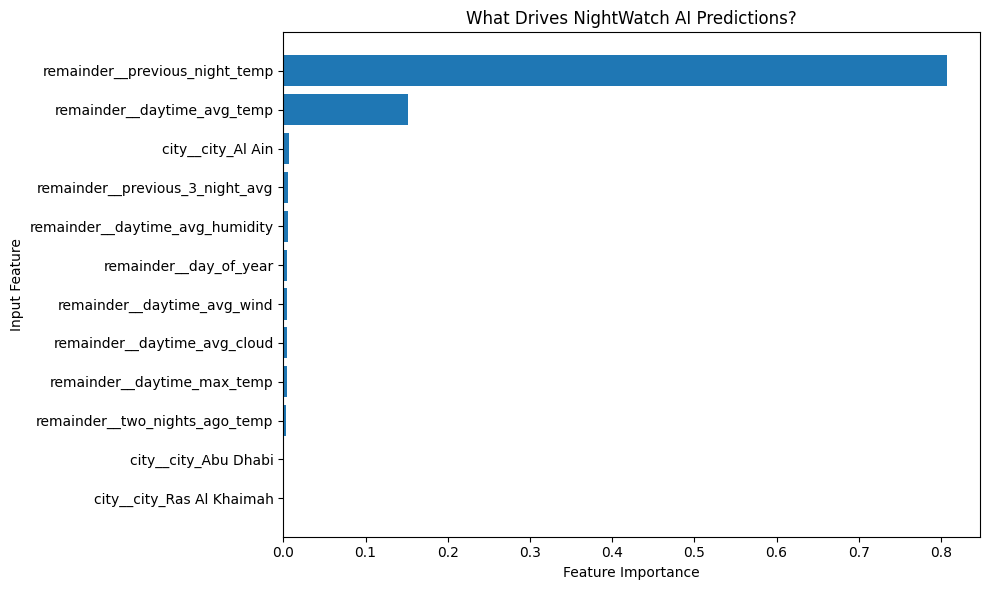

In [ ]:

# STEP 16: Random Forest Feature Importance

import pandas as pd
import matplotlib.pyplot as plt

# Get feature names after preprocessing
feature_names = (
    model.named_steps["preprocessor"]
    .get_feature_names_out()
)

# Extract importance scores
importance_values = (
    model.named_steps["regressor"]
    .feature_importances_
)

# Create importance table
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
)

print("RANDOM FOREST FEATURE IMPORTANCE")
display(importance_df)

# Visualize the top 12 features
top_features = importance_df.head(12).sort_values(
    "Importance"
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Input Feature")
plt.title("What Drives NightWatch AI Predictions?")
plt.tight_layout()
plt.show()


In [ ]:

# STEP 17: Ablation experiment

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

# Model using ONLY previous night's temperature
simple_features = ["previous_night_temp"]

simple_model = RandomForestRegressor(
    n_estimators=250,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

simple_model.fit(
    train_df[simple_features],
    y_train
)

simple_predictions = simple_model.predict(
    test_df[simple_features]
)

# Compare predictions
ablation_results = pd.DataFrame([
    {
        "Model": "Full Random Forest",
        "MAE": mean_absolute_error(y_test, predictions)
    },
    {
        "Model": "Previous Night Only",
        "MAE": mean_absolute_error(y_test, simple_predictions)
    },
    {
        "Model": "Persistence Baseline",
        "MAE": mean_absolute_error(
            y_test,
            test_df["previous_night_temp"]
        )
    }
])

ablation_results["MAE"] = ablation_results["MAE"].round(3)

print("FEATURE ABLATION RESULTS")
display(ablation_results)


FEATURE ABLATION RESULTS


,Model,MAE
0,Full Random Forest,0.841
1,Previous Night Only,1.199
2,Persistence Baseline,1.100


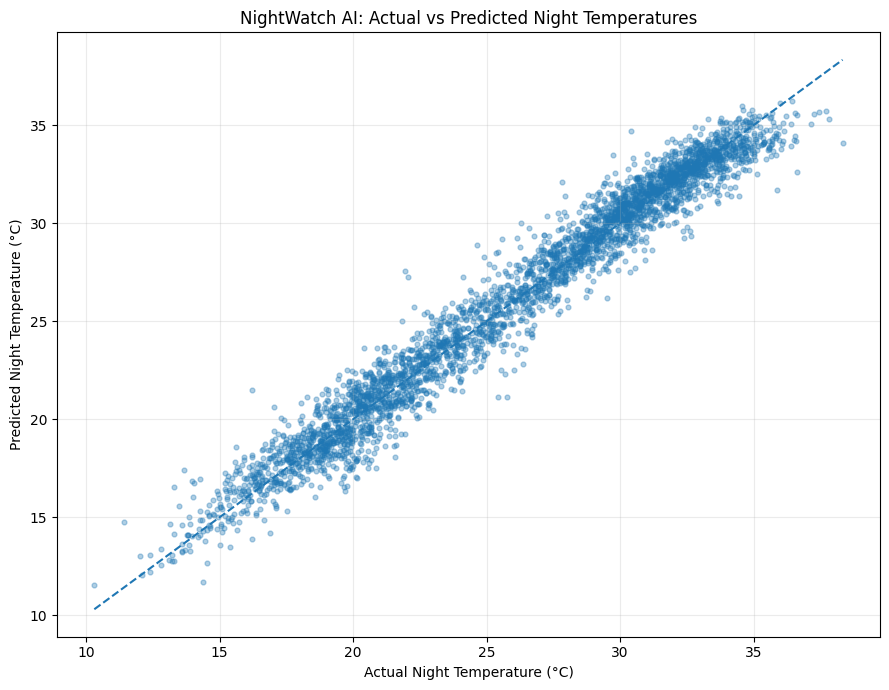

In [ ]:

# STEP 18: Actual vs Predicted Temperature

import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(9, 7))

plt.scatter(
    y_test,
    predictions,
    alpha=0.35,
    s=12
)

# Perfect prediction reference line
minimum = min(y_test.min(), predictions.min())
maximum = max(y_test.max(), predictions.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel("Actual Night Temperature (°C)")
plt.ylabel("Predicted Night Temperature (°C)")

plt.title(
    "NightWatch AI: Actual vs Predicted Night Temperatures"
)

plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


In [ ]:

# STEP 19: Temperature Anomaly Detection

# Calculate training residuals
train_predictions = model.predict(X_train)

train_residuals = y_train.values - train_predictions

# Establish anomaly threshold using training data only
residual_mean = np.mean(train_residuals)
residual_std = np.std(train_residuals)

anomaly_threshold = 2 * residual_std

# Create test prediction analysis
anomaly_df = test_df[
    ["city", "date", "night_avg_temp"]
].copy()

anomaly_df["predicted_temp"] = predictions

anomaly_df["prediction_error"] = (
    anomaly_df["night_avg_temp"] -
    anomaly_df["predicted_temp"]
)

# Positive errors mean the actual night was warmer than predicted
anomaly_df["anomaly"] = (
    anomaly_df["prediction_error"] > anomaly_threshold
)

print("ANOMALY DETECTION RESULTS")
print("Residual standard deviation:", round(residual_std, 3), "°C")
print("Warm anomaly threshold:", round(anomaly_threshold, 3), "°C")

print(
    "Unusually warm nights detected:",
    anomaly_df["anomaly"].sum()
)

print(
    "Percentage of test nights flagged:",
    round(anomaly_df["anomaly"].mean() * 100, 2),
    "%"
)

print("\nTOP WARM ANOMALIES")

display(
    anomaly_df[anomaly_df["anomaly"]]
    .sort_values("prediction_error", ascending=False)
    .head(15)
)


ANOMALY DETECTION RESULTS
Residual standard deviation: 0.476 °C
Warm anomaly threshold: 0.953 °C
Unusually warm nights detected: 558
Percentage of test nights flagged: 15.29 %

TOP WARM ANOMALIES


,city,date,night_avg_temp,predicted_temp,prediction_error,anomaly
8364,Dubai,2024-12-06,25.755556,21.114557,4.640999,True
14200,Sharjah,2024-12-06,25.422222,21.157151,4.265071,True
2780,Abu Dhabi,2025-08-15,38.333333,34.081256,4.252077,True
11092,Ras Al Khaimah,2024-05-30,35.866667,31.686241,4.180426,True
5317,Al Ain,2024-07-30,36.644444,32.627100,4.017344,True
5137,Al Ain,2024-02-01,26.366667,22.838153,3.528514,True
5821,Al Ain,2025-12-16,21.588889,18.083437,3.505452,True
5779,Al Ain,2025-11-04,26.011111,22.530505,3.480606,True
11053,Ras Al Khaimah,2024-04-21,25.700000,22.300672,3.399328,True
14245,Sharjah,2025-01-20,19.711111,16.330849,3.380262,True


In [ ]:

# STEP 20: Calibrate warm anomaly threshold
# Use 2023 as a separate validation period

from sklearn.base import clone
import numpy as np
import pandas as pd

# Split historical data
calibration_train = prepared_df[
    prepared_df["date"] < "2023-01-01"
].copy()

calibration_data = prepared_df[
    (prepared_df["date"] >= "2023-01-01") &
    (prepared_df["date"] < "2024-01-01")
].copy()

# Train a separate calibration model
calibration_model = clone(model)

calibration_model.fit(
    calibration_train[features],
    calibration_train[target]
)

# Predict 2023 temperatures
calibration_predictions = calibration_model.predict(
    calibration_data[features]
)

# Calculate signed prediction residuals
calibration_residuals = (
    calibration_data[target].values -
    calibration_predictions
)

# Use the 95th percentile as the warm-anomaly threshold
warm_threshold = np.quantile(
    calibration_residuals,
    0.95
)

print("ANOMALY THRESHOLD CALIBRATION")
print("Calibration records:", len(calibration_data))
print("Warm anomaly threshold:", round(warm_threshold, 3), "°C")

# Apply threshold to untouched 2024-2025 test predictions
anomaly_df = test_df[
    ["city", "date", "night_avg_temp"]
].copy()

anomaly_df["predicted_temp"] = predictions

anomaly_df["prediction_error"] = (
    anomaly_df["night_avg_temp"] -
    anomaly_df["predicted_temp"]
)

anomaly_df["warm_anomaly"] = (
    anomaly_df["prediction_error"] > warm_threshold
)

print("\nFINAL ANOMALY RESULTS")
print(
    "Warm anomalies detected:",
    anomaly_df["warm_anomaly"].sum()
)

print(
    "Percentage flagged:",
    round(anomaly_df["warm_anomaly"].mean() * 100, 2),
    "%"
)

print("\nTOP 15 WARM ANOMALIES")

display(
    anomaly_df[anomaly_df["warm_anomaly"]]
    .sort_values("prediction_error", ascending=False)
    .head(15)
)


ANOMALY THRESHOLD CALIBRATION
Calibration records: 1825
Warm anomaly threshold: 1.715 °C

FINAL ANOMALY RESULTS
Warm anomalies detected: 185
Percentage flagged: 5.07 %

TOP 15 WARM ANOMALIES


,city,date,night_avg_temp,predicted_temp,prediction_error,warm_anomaly
8364,Dubai,2024-12-06,25.755556,21.114557,4.640999,True
14200,Sharjah,2024-12-06,25.422222,21.157151,4.265071,True
2780,Abu Dhabi,2025-08-15,38.333333,34.081256,4.252077,True
11092,Ras Al Khaimah,2024-05-30,35.866667,31.686241,4.180426,True
5317,Al Ain,2024-07-30,36.644444,32.627100,4.017344,True
5137,Al Ain,2024-02-01,26.366667,22.838153,3.528514,True
5821,Al Ain,2025-12-16,21.588889,18.083437,3.505452,True
5779,Al Ain,2025-11-04,26.011111,22.530505,3.480606,True
11053,Ras Al Khaimah,2024-04-21,25.700000,22.300672,3.399328,True
14245,Sharjah,2025-01-20,19.711111,16.330849,3.380262,True


WARM ANOMALIES BY CITY


,Total_Nights,Warm_Anomalies,Anomaly_Percentage
city,,,
Al Ain,730,54,7.40
Ras Al Khaimah,730,42,5.75
Dubai,730,39,5.34
Sharjah,730,35,4.79
Abu Dhabi,730,15,2.05



WARM ANOMALIES BY YEAR


,Total_Nights,Warm_Anomalies,Anomaly_Percentage
year,,,
2024,1830,106,5.79
2025,1820,79,4.34


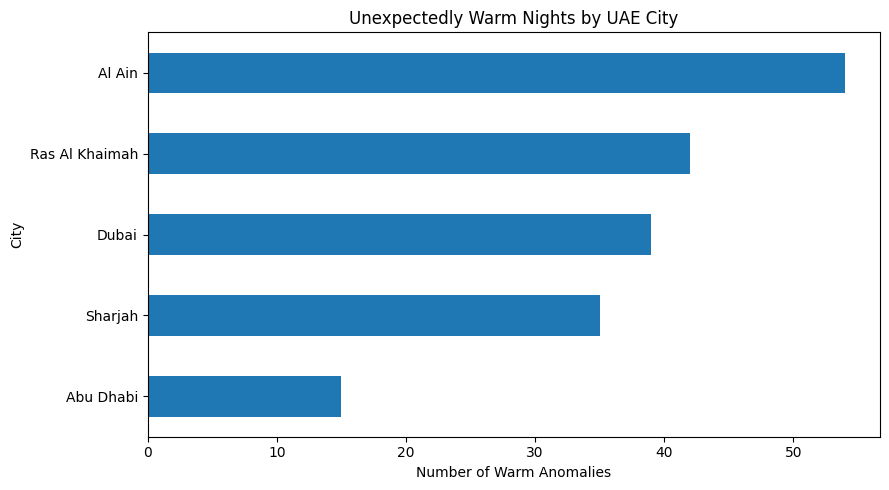

In [ ]:

# STEP 21: Anomaly distribution by city and year

# Count anomalies by city
city_anomalies = (
    anomaly_df.groupby("city")
    .agg(
        Total_Nights=("warm_anomaly", "count"),
        Warm_Anomalies=("warm_anomaly", "sum")
    )
)

city_anomalies["Anomaly_Percentage"] = (
    city_anomalies["Warm_Anomalies"] /
    city_anomalies["Total_Nights"] * 100
).round(2)

print("WARM ANOMALIES BY CITY")
display(city_anomalies.sort_values(
    "Anomaly_Percentage",
    ascending=False
))

# Count anomalies by year
anomaly_df["year"] = pd.to_datetime(
    anomaly_df["date"]
).dt.year

year_anomalies = (
    anomaly_df.groupby("year")
    .agg(
        Total_Nights=("warm_anomaly", "count"),
        Warm_Anomalies=("warm_anomaly", "sum")
    )
)

year_anomalies["Anomaly_Percentage"] = (
    year_anomalies["Warm_Anomalies"] /
    year_anomalies["Total_Nights"] * 100
).round(2)

print("\nWARM ANOMALIES BY YEAR")
display(year_anomalies)

# Visualize city-level anomaly counts
city_anomalies["Warm_Anomalies"].sort_values().plot(
    kind="barh",
    figsize=(9, 5),
    title="Unexpectedly Warm Nights by UAE City"
)

plt.xlabel("Number of Warm Anomalies")
plt.ylabel("City")
plt.tight_layout()
plt.show()


WARM ANOMALIES BY MONTH


,Total_Nights,Warm_Anomalies,Anomaly_Percentage
month,,,
January,310,28,9.03
February,285,24,8.42
March,310,20,6.45
May,310,19,6.13
December,305,18,5.90
July,310,17,5.48
August,310,15,4.84
April,300,12,4.00
June,300,12,4.00


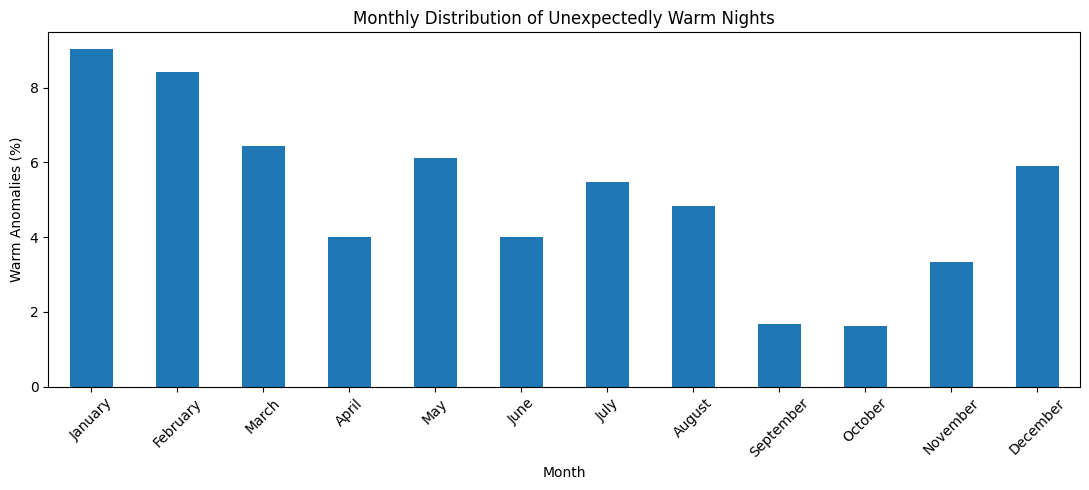

In [ ]:

# STEP 22: Monthly warm anomaly analysis

anomaly_df["date"] = pd.to_datetime(anomaly_df["date"])

anomaly_df["month"] = anomaly_df["date"].dt.month

monthly_anomalies = (
    anomaly_df.groupby("month")
    .agg(
        Total_Nights=("warm_anomaly", "count"),
        Warm_Anomalies=("warm_anomaly", "sum")
    )
)

monthly_anomalies["Anomaly_Percentage"] = (
    monthly_anomalies["Warm_Anomalies"] /
    monthly_anomalies["Total_Nights"] * 100
).round(2)

month_names = {
    1: "January", 2: "February", 3: "March",
    4: "April", 5: "May", 6: "June",
    7: "July", 8: "August", 9: "September",
    10: "October", 11: "November", 12: "December"
}

monthly_anomalies.index = (
    monthly_anomalies.index.map(month_names)
)

print("WARM ANOMALIES BY MONTH")
display(
    monthly_anomalies.sort_values(
        "Anomaly_Percentage",
        ascending=False
    )
)

# Visualize monthly anomaly percentages
monthly_anomalies["Anomaly_Percentage"].plot(
    kind="bar",
    figsize=(11, 5),
    title="Monthly Distribution of Unexpectedly Warm Nights"
)

plt.ylabel("Warm Anomalies (%)")
plt.xlabel("Month")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


MONTHLY PREDICTION BIAS


,Average_Error,Median_Error,Warm_Anomalies,Total_Nights,Anomaly_Percentage
month,,,,,
1,0.125,0.073,28,310,9.03
2,0.087,0.205,24,285,8.42
12,0.057,-0.006,18,305,5.90
8,0.023,-0.024,15,310,4.84
10,-0.043,-0.058,5,310,1.61
7,-0.074,-0.175,17,310,5.48
11,-0.147,-0.206,10,300,3.33
3,-0.212,-0.301,20,310,6.45
5,-0.214,-0.256,19,310,6.13


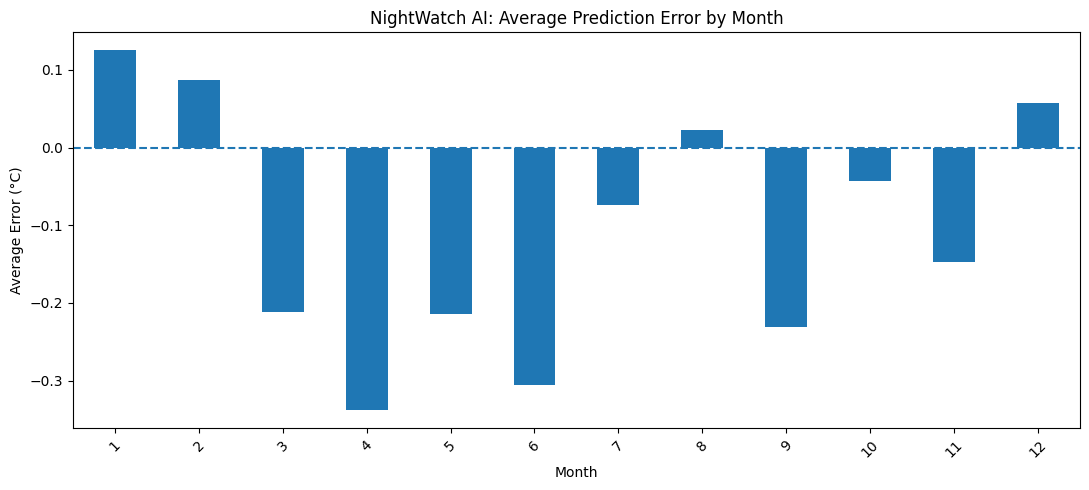

In [ ]:

# STEP 23: Monthly prediction bias analysis

monthly_bias = (
    anomaly_df.groupby("month")
    .agg(
        Average_Error=("prediction_error", "mean"),
        Median_Error=("prediction_error", "median"),
        Warm_Anomalies=("warm_anomaly", "sum"),
        Total_Nights=("warm_anomaly", "count")
    )
)

monthly_bias["Average_Error"] = (
    monthly_bias["Average_Error"].round(3)
)

monthly_bias["Median_Error"] = (
    monthly_bias["Median_Error"].round(3)
)

monthly_bias["Anomaly_Percentage"] = (
    monthly_bias["Warm_Anomalies"] /
    monthly_bias["Total_Nights"] * 100
).round(2)

print("MONTHLY PREDICTION BIAS")
display(monthly_bias.sort_values("Average_Error", ascending=False))

# Visualize average prediction error
monthly_bias["Average_Error"].plot(
    kind="bar",
    figsize=(11, 5),
    title="NightWatch AI: Average Prediction Error by Month"
)

plt.axhline(0, linestyle="--")
plt.ylabel("Average Error (°C)")
plt.xlabel("Month")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [ ]:

# STEP 24: City-specific anomaly threshold calibration

# Create calibration results table
calibration_results = calibration_data[
    ["city", "date", target]
].copy()

calibration_results["prediction"] = calibration_predictions

calibration_results["residual"] = (
    calibration_results[target] -
    calibration_results["prediction"]
)

# Calculate a separate 95th percentile threshold for each city
city_thresholds = (
    calibration_results.groupby("city")["residual"]
    .quantile(0.95)
)

print("CITY-SPECIFIC WARM ANOMALY THRESHOLDS")
display(city_thresholds.round(3))

# Apply each city's threshold to the test dataset
anomaly_df["city_threshold"] = (
    anomaly_df["city"].map(city_thresholds)
)

anomaly_df["city_adjusted_anomaly"] = (
    anomaly_df["prediction_error"] >
    anomaly_df["city_threshold"]
)

# Compare global and city-specific results
comparison_anomalies = anomaly_df.groupby("city").agg(
    Total_Nights=("warm_anomaly", "count"),
    Global_Anomalies=("warm_anomaly", "sum"),
    City_Adjusted_Anomalies=("city_adjusted_anomaly", "sum")
)

comparison_anomalies["Global_Rate_%"] = (
    comparison_anomalies["Global_Anomalies"] /
    comparison_anomalies["Total_Nights"] * 100
).round(2)

comparison_anomalies["City_Adjusted_Rate_%"] = (
    comparison_anomalies["City_Adjusted_Anomalies"] /
    comparison_anomalies["Total_Nights"] * 100
).round(2)

print("\nGLOBAL VS CITY-SPECIFIC ANOMALY DETECTION")
display(comparison_anomalies)


CITY-SPECIFIC WARM ANOMALY THRESHOLDS


,residual
city,
Abu Dhabi,1.403
Al Ain,1.791
Dubai,1.408
Ras Al Khaimah,2.116
Sharjah,1.430



GLOBAL VS CITY-SPECIFIC ANOMALY DETECTION


,Total_Nights,Global_Anomalies,City_Adjusted_Anomalies,Global_Rate_%,City_Adjusted_Rate_%
city,,,,,
Abu Dhabi,730,15,35,2.05,4.79
Al Ain,730,54,49,7.40,6.71
Dubai,730,39,59,5.34,8.08
Ras Al Khaimah,730,42,23,5.75,3.15
Sharjah,730,35,56,4.79,7.67


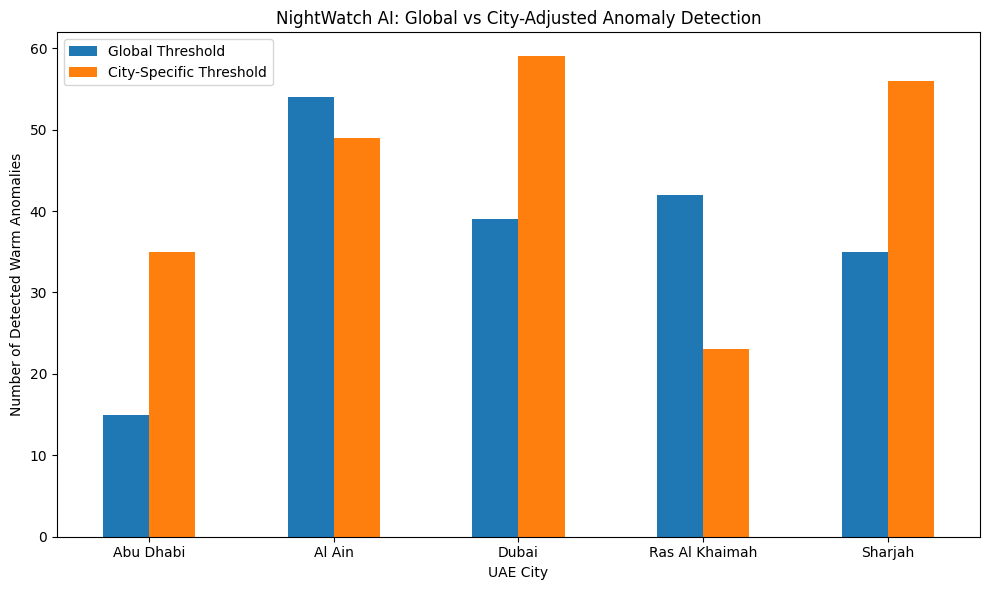

TOTAL GLOBAL ANOMALIES: 185
TOTAL CITY-ADJUSTED ANOMALIES: 222


In [ ]:

# STEP 25: Compare anomaly detection methods

comparison_anomalies[
    ["Global_Anomalies", "City_Adjusted_Anomalies"]
].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title(
    "NightWatch AI: Global vs City-Adjusted Anomaly Detection"
)

plt.xlabel("UAE City")
plt.ylabel("Number of Detected Warm Anomalies")

plt.xticks(rotation=0)
plt.legend([
    "Global Threshold",
    "City-Specific Threshold"
])

plt.tight_layout()
plt.show()

print("TOTAL GLOBAL ANOMALIES:",
      comparison_anomalies["Global_Anomalies"].sum())

print("TOTAL CITY-ADJUSTED ANOMALIES:",
      comparison_anomalies["City_Adjusted_Anomalies"].sum())


In [ ]:

# CHECK WHICH DATA AND MODEL VARIABLES ARE AVAILABLE

print("AVAILABLE DATAFRAMES:")
for name, obj in globals().copy().items():
    if isinstance(obj, __import__('pandas').DataFrame):
        print(f"\n{name}")
        print("Shape:", obj.shape)
        print("Columns:", obj.columns.tolist())

print("\nAVAILABLE MODELS:")
for name in ["rf_model", "xgb_model", "lstm_model"]:
    if name in globals():
        print(name, "FOUND")
    else:
        print(name, "not found")


AVAILABLE DATAFRAMES:

city_df
Shape: (70128, 6)
Columns: ['time', 'temperature_2m', 'relative_humidity_2m', 'wind_speed_10m', 'cloud_cover', 'city']

df
Shape: (350640, 6)
Columns: ['time', 'temperature_2m', 'relative_humidity_2m', 'wind_speed_10m', 'cloud_cover', 'city']

df_test
Shape: (17544, 5)
Columns: ['time', 'temperature_2m', 'relative_humidity_2m', 'wind_speed_10m', 'cloud_cover']

yearly_df
Shape: (8760, 6)
Columns: ['time', 'temperature_2m', 'relative_humidity_2m', 'wind_speed_10m', 'cloud_cover', 'city']

daytime
Shape: (189930, 8)
Columns: ['time', 'temperature_2m', 'relative_humidity_2m', 'wind_speed_10m', 'cloud_cover', 'city', 'date', 'hour']

day_features
Shape: (14610, 7)
Columns: ['city', 'date', 'daytime_avg_temp', 'daytime_max_temp', 'daytime_avg_humidity', 'daytime_avg_wind', 'daytime_avg_cloud']

night
Shape: (131490, 9)
Columns: ['time', 'temperature_2m', 'relative_humidity_2m', 'wind_speed_10m', 'cloud_cover', 'city', 'date', 'hour', 'night_date']

night_targe

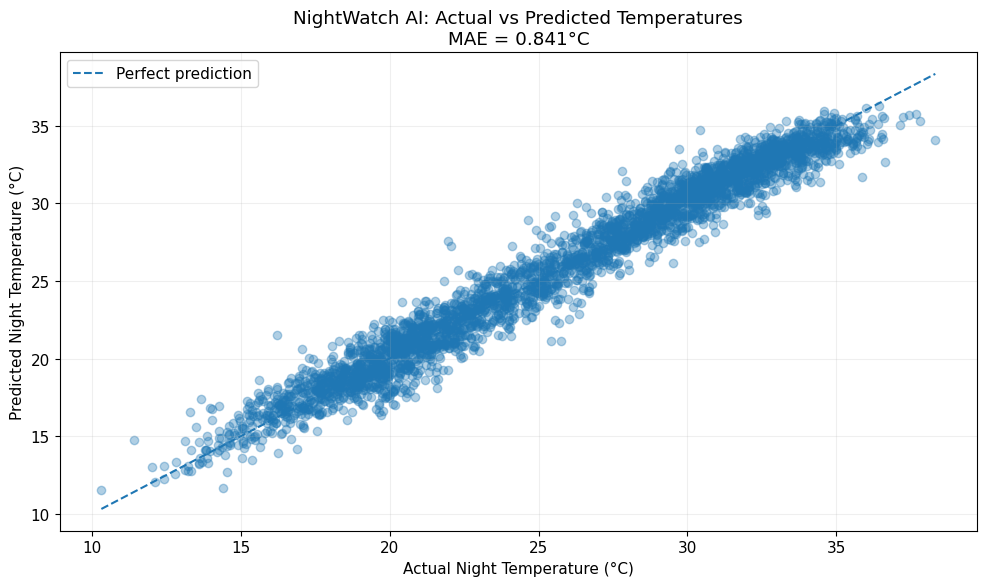

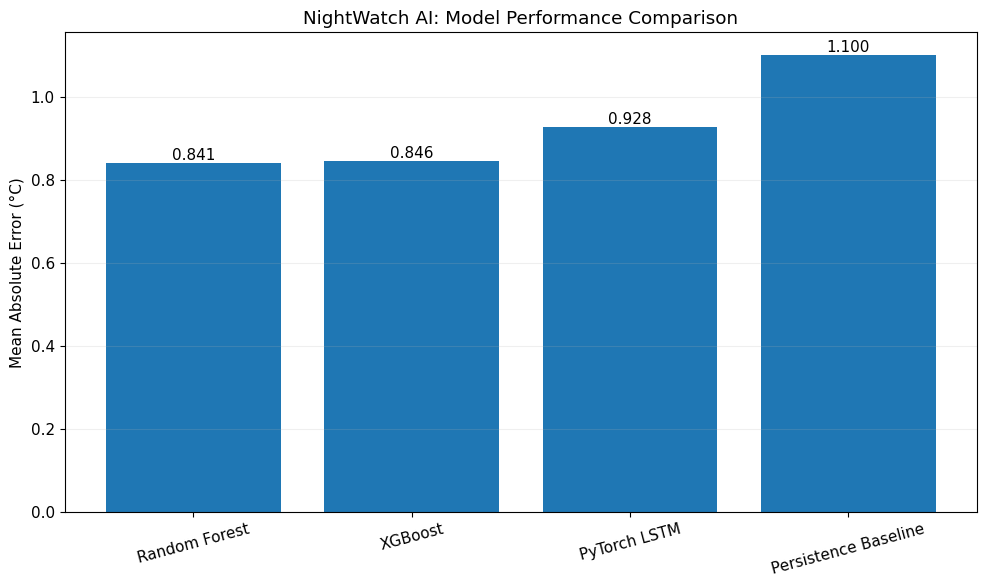

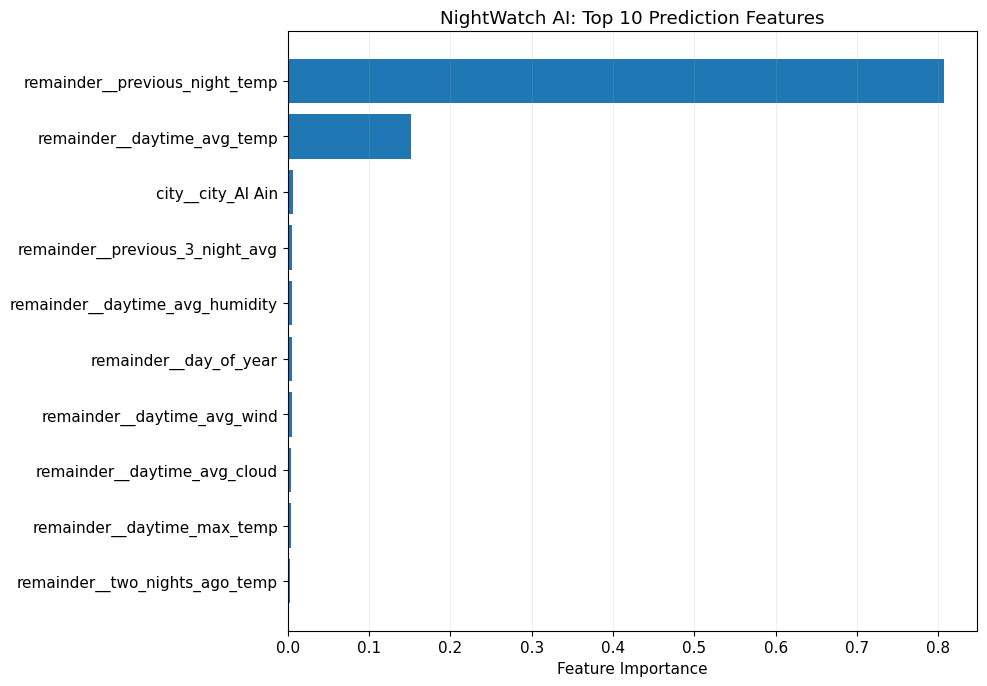

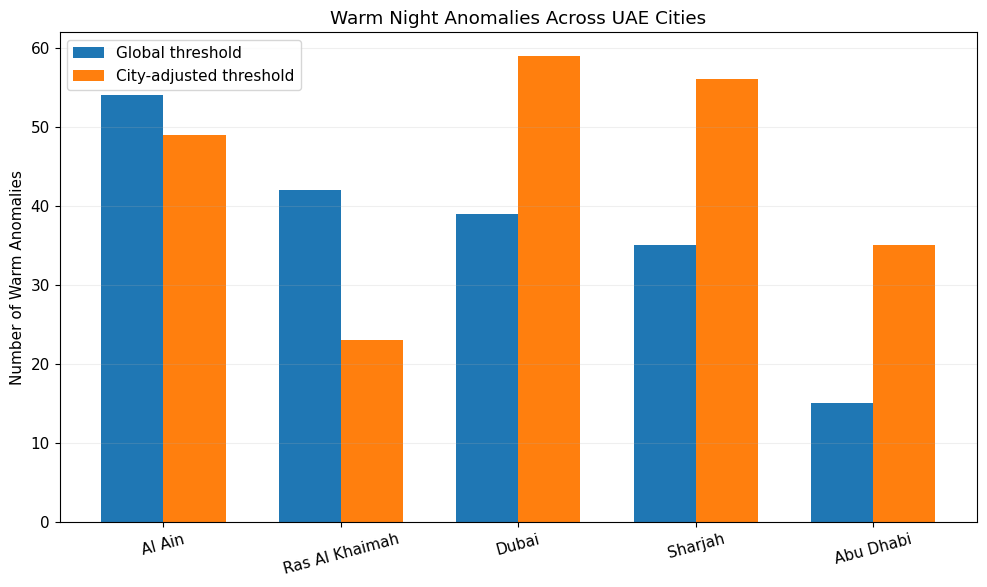

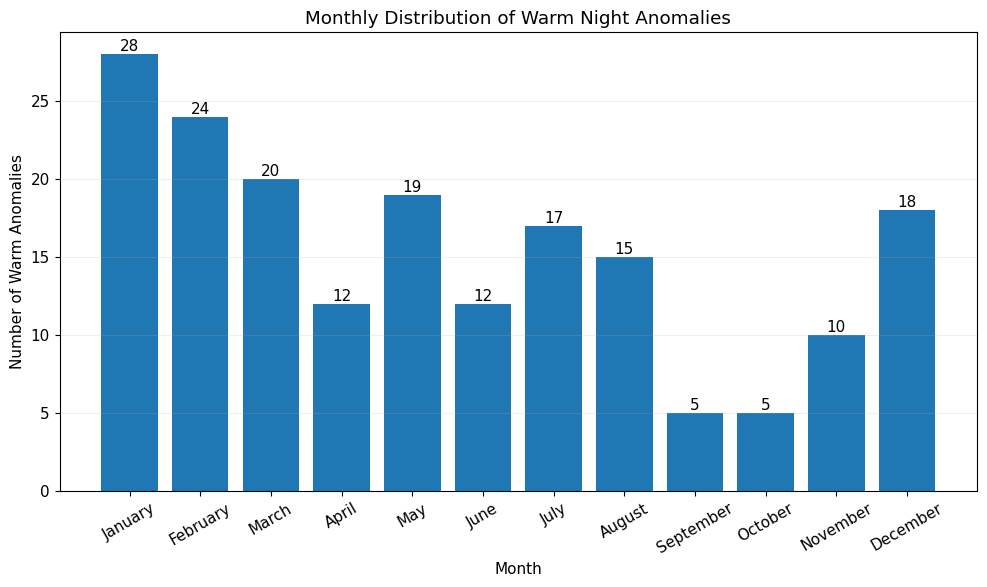


ALL FIVE VISUALIZATIONS GENERATED!
Saved files:
01_actual_vs_predicted.png
02_model_comparison.png
03_feature_importance.png
04_city_anomalies.png
05_monthly_anomalies.png


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# Create a folder for our final charts
os.makedirs("/content/nightwatch_visuals", exist_ok=True)

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 11

# --------------------------------------------------
# CHART 1: ACTUAL VS PREDICTED NIGHT TEMPERATURE
# --------------------------------------------------

actual = anomaly_df["night_avg_temp"]
predicted = anomaly_df["predicted_temp"]

mae = np.mean(np.abs(actual - predicted))

plt.figure()
plt.scatter(actual, predicted, alpha=0.35)
minimum = min(actual.min(), predicted.min())
maximum = max(actual.max(), predicted.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--",
    label="Perfect prediction"
)

plt.xlabel("Actual Night Temperature (°C)")
plt.ylabel("Predicted Night Temperature (°C)")
plt.title(f"NightWatch AI: Actual vs Predicted Temperatures\nMAE = {mae:.3f}°C")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig("/content/nightwatch_visuals/01_actual_vs_predicted.png", dpi=300)
plt.show()


# --------------------------------------------------
# CHART 2: MODEL PERFORMANCE COMPARISON
# --------------------------------------------------

performance = corrected_results.copy()
performance = performance.sort_values("MAE (°C)")

plt.figure()
bars = plt.bar(
    performance["Model"],
    performance["MAE (°C)"]
)

plt.bar_label(bars, fmt="%.3f")
plt.ylabel("Mean Absolute Error (°C)")
plt.title("NightWatch AI: Model Performance Comparison")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.savefig("/content/nightwatch_visuals/02_model_comparison.png", dpi=300)
plt.show()


# --------------------------------------------------
# CHART 3: FEATURE IMPORTANCE
# --------------------------------------------------

features = importance_df.sort_values(
    "Importance", ascending=True
).tail(10)

plt.figure(figsize=(10, 7))
plt.barh(features["Feature"], features["Importance"])

plt.xlabel("Feature Importance")
plt.title("NightWatch AI: Top 10 Prediction Features")
plt.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.savefig("/content/nightwatch_visuals/03_feature_importance.png", dpi=300)
plt.show()


# --------------------------------------------------
# CHART 4: WARM ANOMALIES BY CITY
# --------------------------------------------------

city_chart = comparison_anomalies.copy().reset_index()

# Give the first column a consistent name
city_chart = city_chart.rename(columns={city_chart.columns[0]: "City"})

city_chart = city_chart.sort_values("Global_Anomalies", ascending=False)

x = np.arange(len(city_chart))
width = 0.35

plt.figure()
plt.bar(
    x - width/2,
    city_chart["Global_Anomalies"],
    width,
    label="Global threshold"
)

plt.bar(
    x + width/2,
    city_chart["City_Adjusted_Anomalies"],
    width,
    label="City-adjusted threshold"
)

plt.xticks(x, city_chart["City"], rotation=15)
plt.ylabel("Number of Warm Anomalies")
plt.title("Warm Night Anomalies Across UAE Cities")
plt.legend()
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.savefig("/content/nightwatch_visuals/04_city_anomalies.png", dpi=300)
plt.show()


# --------------------------------------------------
# CHART 5: WARM ANOMALIES BY MONTH
# --------------------------------------------------

monthly_chart = monthly_anomalies.copy().reset_index()
monthly_chart = monthly_chart.rename(
    columns={monthly_chart.columns[0]: "Month"}
)

# Sort chronologically if month values are numbers
if pd.api.types.is_numeric_dtype(monthly_chart["Month"]):
    monthly_chart = monthly_chart.sort_values("Month")

plt.figure()
bars = plt.bar(
    monthly_chart["Month"].astype(str),
    monthly_chart["Warm_Anomalies"]
)

plt.bar_label(bars)
plt.xlabel("Month")
plt.ylabel("Number of Warm Anomalies")
plt.title("Monthly Distribution of Warm Night Anomalies")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.savefig("/content/nightwatch_visuals/05_monthly_anomalies.png", dpi=300)
plt.show()


# --------------------------------------------------
# FINAL CONFIRMATION
# --------------------------------------------------

print("\nALL FIVE VISUALIZATIONS GENERATED!")
print("Saved files:")

for file in sorted(os.listdir("/content/nightwatch_visuals")):
    print(file)


In [ ]:

import joblib
import os

print("MODEL TYPE:", type(xgb_model))
print("\nMODEL DETAILS:")

try:
    print("Expected input features:", xgb_model.n_features_in_)
except:
    print("Feature count unavailable")

try:
    print("Feature names:", xgb_model.get_booster().feature_names)
except:
    print("Feature names unavailable")

print("\nTRAINING DATA TYPES:")
print(X_train.dtypes)

print("\nTEST DATA SAMPLE:")
display(X_test.head())

print("\nMODEL FILE CHECK:")
print("XGBoost model available:", xgb_model is not None)


MODEL TYPE: <class 'sklearn.pipeline.Pipeline'>

MODEL DETAILS:
Expected input features: 11
Feature names unavailable

TRAINING DATA TYPES:
city                     object
daytime_avg_temp        float64
daytime_max_temp        float64
daytime_avg_humidity    float64
daytime_avg_wind        float64
daytime_avg_cloud       float64
month                     int32
day_of_year               int32
previous_night_temp     float64
two_nights_ago_temp     float64
previous_3_night_avg    float64
dtype: object

TEST DATA SAMPLE:


,city,daytime_avg_temp,daytime_max_temp,daytime_avg_humidity,daytime_avg_wind,daytime_avg_cloud,month,day_of_year,previous_night_temp,two_nights_ago_temp,previous_3_night_avg
2188,Abu Dhabi,24.338462,26.1,69.307692,15.146154,1.692308,1,1,22.700000,21.622222,21.933333
2189,Abu Dhabi,24.115385,25.3,61.076923,23.830769,2.000000,1,2,22.655556,22.700000,22.325926
2190,Abu Dhabi,23.338462,25.0,60.384615,19.246154,35.384615,1,3,21.233333,22.655556,22.196296
2191,Abu Dhabi,23.284615,24.3,58.153846,27.300000,17.076923,1,4,22.133333,21.233333,22.007407
2192,Abu Dhabi,23.376923,24.6,51.461538,18.669231,34.846154,1,5,21.600000,22.133333,21.655556



MODEL FILE CHECK:
XGBoost model available: True


In [ ]:

import os
import json
import joblib
import zipfile
import pandas as pd

# Create project folder
PROJECT = "/content/NightWatch_AI"
os.makedirs(PROJECT, exist_ok=True)

# 1. Save trained XGBoost pipeline
joblib.dump(xgb_model, f"{PROJECT}/nightwatch_model.joblib")

# 2. Save historical dataset
prepared_df.to_csv(
    f"{PROJECT}/historical_data.csv", index=False
)

# 3. Save anomaly detection data
anomaly_df.to_csv(
    f"{PROJECT}/anomaly_data.csv", index=False
)

# 4. Save model performance
corrected_results.to_csv(
    f"{PROJECT}/model_performance.csv", index=False
)

# 5. Save feature importance
importance_df.to_csv(
    f"{PROJECT}/feature_importance.csv", index=False
)

# 6. Save city anomaly statistics
comparison_anomalies.to_csv(
    f"{PROJECT}/city_anomalies.csv"
)

# 7. Save monthly anomaly statistics
monthly_anomalies.to_csv(
    f"{PROJECT}/monthly_anomalies.csv"
)

# 8. Save model configuration
metadata = {
    "project_name": "NightWatch AI",
    "model": "XGBoost",
    "input_features": X_train.columns.tolist(),
    "global_warm_anomaly_threshold": 1.718,
    "city_thresholds": {
        "Abu Dhabi": 1.400,
        "Al Ain": 1.782,
        "Dubai": 1.403,
        "Ras Al Khaimah": 2.115,
        "Sharjah": 1.418
    },
    "prediction_unit": "Celsius",
    "cities": [
        "Abu Dhabi",
        "Al Ain",
        "Dubai",
        "Ras Al Khaimah",
        "Sharjah"
    ]
}

with open(f"{PROJECT}/metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)

# 9. Create requirements file
requirements = """streamlit
pandas
numpy
matplotlib
plotly
scikit-learn
xgboost
joblib
"""

with open(f"{PROJECT}/requirements.txt", "w") as f:
    f.write(requirements)

# 10. Package everything into ZIP
zip_path = "/content/NightWatch_AI.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for root, dirs, files in os.walk(PROJECT):
        for file in files:
            full_path = os.path.join(root, file)
            relative_path = os.path.relpath(full_path, PROJECT)
            z.write(full_path, relative_path)

print("NIGHTWATCH AI MODEL PACKAGE CREATED!")
print("\nFiles included:")

for file in sorted(os.listdir(PROJECT)):
    print("✔", file)

print("\nZIP SIZE:", round(os.path.getsize(zip_path) / 1024, 2), "KB")

# Verify that the saved model can load and predict
loaded_model = joblib.load(f"{PROJECT}/nightwatch_model.joblib")
sample_prediction = loaded_model.predict(X_test.head(5))

print("\nMODEL VERIFICATION:")
print("Loaded successfully!")
print("Sample predictions:", sample_prediction)


NIGHTWATCH AI MODEL PACKAGE CREATED!

Files included:
✔ anomaly_data.csv
✔ city_anomalies.csv
✔ feature_importance.csv
✔ historical_data.csv
✔ metadata.json
✔ model_performance.csv
✔ monthly_anomalies.csv
✔ nightwatch_model.joblib
✔ requirements.txt

ZIP SIZE: 927.95 KB

MODEL VERIFICATION:
Loaded successfully!
Sample predictions: [21.152699 21.287127 20.967623 21.05076  20.684538]


In [ ]:

%%writefile /content/NightWatch_AI/app.py

import streamlit as st
import pandas as pd
import numpy as np
import joblib
import json
import plotly.express as px
from datetime import date

# -----------------------------------------
# PAGE CONFIGURATION
# -----------------------------------------

st.set_page_config(
    page_title="NightWatch AI",
    page_icon="🌙",
    layout="wide"
)

# -----------------------------------------
# LOAD PROJECT FILES
# -----------------------------------------

@st.cache_resource
def load_model():
    return joblib.load("nightwatch_model.joblib")

@st.cache_data
def load_data():
    historical = pd.read_csv("historical_data.csv")
    anomalies = pd.read_csv("anomaly_data.csv")
    performance = pd.read_csv("model_performance.csv")
    importance = pd.read_csv("feature_importance.csv")
    cities = pd.read_csv("city_anomalies.csv", index_col=0)
    monthly = pd.read_csv("monthly_anomalies.csv", index_col=0)

    with open("metadata.json") as f:
        metadata = json.load(f)

    historical["date"] = pd.to_datetime(historical["date"])
    anomalies["date"] = pd.to_datetime(anomalies["date"])

    return historical, anomalies, performance, importance, cities, monthly, metadata

model = load_model()

historical, anomalies, performance, importance, cities, monthly, metadata = load_data()

# -----------------------------------------
# HEADER
# -----------------------------------------

st.title("🌙 NightWatch AI")
st.subheader("AI-powered nighttime temperature prediction and warm anomaly detection")

st.markdown(
    "Monitoring nighttime temperature patterns across five UAE cities "
    "using machine learning."
)

st.divider()

# -----------------------------------------
# MODEL PERFORMANCE
# -----------------------------------------

st.header("Model Performance")

xgb_row = performance[
    performance["Model"].str.contains("XGBoost", case=False)
]

if not xgb_row.empty:
    mae = xgb_row.iloc[0]["MAE (°C)"]
    rmse = xgb_row.iloc[0]["RMSE (°C)"]
    r2 = xgb_row.iloc[0]["R²"]

    col1, col2, col3 = st.columns(3)

    col1.metric("Mean Absolute Error", f"{mae:.3f} °C")
    col2.metric("Root Mean Squared Error", f"{rmse:.3f} °C")
    col3.metric("R² Score", f"{r2:.3f}")

st.caption("Performance metrics are based on the held-out evaluation dataset.")

st.divider()

# -----------------------------------------
# TEMPERATURE PREDICTION
# -----------------------------------------

st.header("Predict Nighttime Temperature")

st.write(
    "Enter daytime weather measurements and recent nighttime temperatures "
    "to estimate the upcoming night's average temperature."
)

cities_list = metadata["cities"]

city = st.selectbox("Select UAE city", cities_list)

city_history = historical[historical["city"] == city]

# Use city-specific historical medians as sensible starting values
defaults = city_history.median(numeric_only=True)

with st.form("prediction_form"):

    selected_date = st.date_input(
        "Prediction date",
        value=date.today()
    )

    col1, col2 = st.columns(2)

    with col1:
        daytime_avg_temp = st.number_input(
            "Daytime average temperature (°C)",
            value=float(defaults["daytime_avg_temp"])
        )

        daytime_max_temp = st.number_input(
            "Daytime maximum temperature (°C)",
            value=float(defaults["daytime_max_temp"])
        )

        daytime_avg_humidity = st.number_input(
            "Average humidity (%)",
            min_value=0.0,
            max_value=100.0,
            value=float(defaults["daytime_avg_humidity"])
        )

        daytime_avg_wind = st.number_input(
            "Average wind speed (km/h)",
            min_value=0.0,
            value=float(defaults["daytime_avg_wind"])
        )

    with col2:
        daytime_avg_cloud = st.number_input(
            "Average cloud cover (%)",
            min_value=0.0,
            max_value=100.0,
            value=float(defaults["daytime_avg_cloud"])
        )

        previous_night_temp = st.number_input(
            "Previous night's average temperature (°C)",
            value=float(defaults["previous_night_temp"])
        )

        two_nights_ago_temp = st.number_input(
            "Temperature two nights ago (°C)",
            value=float(defaults["two_nights_ago_temp"])
        )

        previous_3_night_avg = st.number_input(
            "Previous 3-night average temperature (°C)",
            value=float(defaults["previous_3_night_avg"])
        )

    submitted = st.form_submit_button("Predict Nighttime Temperature")

if submitted:

    input_data = pd.DataFrame([{
        "city": city,
        "daytime_avg_temp": daytime_avg_temp,
        "daytime_max_temp": daytime_max_temp,
        "daytime_avg_humidity": daytime_avg_humidity,
        "daytime_avg_wind": daytime_avg_wind,
        "daytime_avg_cloud": daytime_avg_cloud,
        "month": selected_date.month,
        "day_of_year": selected_date.timetuple().tm_yday,
        "previous_night_temp": previous_night_temp,
        "two_nights_ago_temp": two_nights_ago_temp,
        "previous_3_night_avg": previous_3_night_avg
    }])

    # Preserve the exact training feature order
    input_data = input_data[metadata["input_features"]]

    prediction = float(model.predict(input_data)[0])

    st.success("Prediction generated successfully!")

    st.metric(
        "Predicted Nighttime Average Temperature",
        f"{prediction:.2f} °C"
    )

    st.info(
        "This is a model prediction, not a confirmed weather observation. "
        "A warm anomaly can only be confirmed after the actual nighttime "
        "temperature is observed and compared with the prediction."
    )

st.divider()

# -----------------------------------------
# HISTORICAL TEMPERATURE TRENDS
# -----------------------------------------

st.header("Historical Nighttime Temperature Trends")

selected_city = st.selectbox(
    "Choose a city for historical analysis",
    cities_list,
    key="historical_city"
)

city_history = historical[
    historical["city"] == selected_city
].sort_values("date")

fig = px.line(
    city_history,
    x="date",
    y="night_avg_temp",
    title=f"Historical Nighttime Temperature: {selected_city}",
    labels={
        "date": "Date",
        "night_avg_temp": "Average Night Temperature (°C)"
    }
)

st.plotly_chart(fig, use_container_width=True)

# -----------------------------------------
# WARM ANOMALY ANALYSIS
# -----------------------------------------

st.header("Warm Night Anomaly Detection")

st.write(
    "These results show unusually warm nights detected in the historical "
    "evaluation period."
)

city_results = cities.reset_index()
city_results = city_results.rename(
    columns={city_results.columns[0]: "City"}
)

fig = px.bar(
    city_results,
    x="City",
    y=["Global_Anomalies", "City_Adjusted_Anomalies"],
    barmode="group",
    title="Warm Anomalies by City",
    labels={
        "value": "Number of anomalies",
        "variable": "Detection method"
    }
)

st.plotly_chart(fig, use_container_width=True)

monthly_results = monthly.copy().reset_index()
monthly_results = monthly_results.rename(
    columns={monthly_results.columns[0]: "Month"}
)

fig = px.bar(
    monthly_results,
    x="Month",
    y="Warm_Anomalies",
    title="Warm Anomalies by Month",
    labels={
        "Warm_Anomalies": "Number of anomalies",
        "Month": "Month"
    }
)

st.plotly_chart(fig, use_container_width=True)

# -----------------------------------------
# FEATURE IMPORTANCE
# -----------------------------------------

st.header("What Influences the Predictions?")

feature_chart = importance.sort_values(
    "Importance", ascending=True
).tail(10)

fig = px.bar(
    feature_chart,
    x="Importance",
    y="Feature",
    orientation="h",
    title="Top 10 Model Features"
)

st.plotly_chart(fig, use_container_width=True)

# -----------------------------------------
# HISTORICAL ANOMALY RECORDS
# -----------------------------------------

st.header("Detected Warm Night Records")

city_anomalies = anomalies[
    (anomalies["city"] == selected_city) &
    (anomalies["warm_anomaly"] == True)
].sort_values("prediction_error", ascending=False)

if not city_anomalies.empty:

    st.dataframe(
        city_anomalies[
            ["date", "night_avg_temp", "predicted_temp", "prediction_error"]
        ],
        use_container_width=True
    )

else:
    st.write("No global-threshold warm anomalies recorded for this city.")

# -----------------------------------------
# FOOTER
# -----------------------------------------

st.divider()

st.caption(
    "NightWatch AI | UAE nighttime temperature analysis | "
    "Machine-learning research prototype"
)


Writing /content/NightWatch_AI/app.py


In [ ]:

import os
import zipfile

# Include the five visualizations in the project
visual_folder = "/content/nightwatch_visuals"
project_folder = "/content/NightWatch_AI"

for filename in os.listdir(visual_folder):
    source = os.path.join(visual_folder, filename)
    destination = os.path.join(project_folder, filename)

    import shutil
    shutil.copy2(source, destination)

# Rebuild ZIP with app.py and visualizations included
zip_path = "/content/NightWatch_AI.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for root, dirs, files in os.walk(project_folder):
        for file in files:
            full_path = os.path.join(root, file)
            relative_path = os.path.relpath(full_path, project_folder)
            z.write(full_path, relative_path)

print("UPDATED NIGHTWATCH AI PACKAGE!")
print("\nProject files:")

for filename in sorted(os.listdir(project_folder)):
    print("✔", filename)

print("\nZIP size:", round(os.path.getsize(zip_path) / 1024, 2), "KB")


UPDATED NIGHTWATCH AI PACKAGE!

Project files:
✔ 01_actual_vs_predicted.png
✔ 02_model_comparison.png
✔ 03_feature_importance.png
✔ 04_city_anomalies.png
✔ 05_monthly_anomalies.png
✔ anomaly_data.csv
✔ app.py
✔ city_anomalies.csv
✔ feature_importance.csv
✔ historical_data.csv
✔ metadata.json
✔ model_performance.csv
✔ monthly_anomalies.csv
✔ nightwatch_model.joblib
✔ requirements.txt

ZIP size: 2217.54 KB


In [ ]:

!pip -q install streamlit plotly


In [ ]:

%cd /content/NightWatch_AI

!streamlit run app.py --server.port 8501 --server.headless true > streamlit.log 2>&1 &


/content/NightWatch_AI


In [ ]:

!sleep 5
!cat streamlit.log




2026-11-15 04:14:22.724 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.86.221.216:8501



In [ ]:

!pip -q install pyngrok


In [ ]:

from pyngrok import ngrok

# Create a temporary public tunnel to Streamlit
public_url = ngrok.connect(8501)

print("YOUR NIGHTWATCH AI DASHBOARD:")
print(public_url)


ERROR:pyngrok.process.ngrok:t=2026-11-15T04:14:39+0000 lvl=eror msg="failed to reconnect session" obj=tunnels.session err="authentication failed: This ngrok session is not authenticated. ngrok requires an account and a valid credential to start a session.\n\nSign up for an account: https://dashboard.ngrok.com/signup\nGet your credential: https://dashboard.ngrok.com/get-started/your-authtoken\r\n\r\nERR_NGROK_4018\r\n"
ERROR:pyngrok.process.ngrok:t=2026-11-15T04:14:39+0000 lvl=eror msg="session closing" obj=tunnels.session err="authentication failed: This ngrok session is not authenticated. ngrok requires an account and a valid credential to start a session.\n\nSign up for an account: https://dashboard.ngrok.com/signup\nGet your credential: https://dashboard.ngrok.com/get-started/your-authtoken\r\n\r\nERR_NGROK_4018\r\n"


PyngrokNgrokError: The ngrok process errored on start: authentication failed: This ngrok session is not authenticated. ngrok requires an account and a valid credential to start a session.\n\nSign up for an account: https://dashboard.ngrok.com/signup\nGet your credential: https://dashboard.ngrok.com/get-started/your-authtoken\r\n\r\nERR_NGROK_4018\r\n.

In [ ]:
from google.colab import files
files.download("/content/NightWatch_AI.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import sys
import sklearn
import xgboost
import numpy
import joblib

print("Python:", sys.version)
print("Scikit-learn:", sklearn.__version__)
print("XGBoost:", xgboost.__version__)
print("NumPy:", numpy.__version__)
print("Joblib:", joblib.__version__)


Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Scikit-learn: 1.6.1
XGBoost: 3.4.1
NumPy: 2.4.6
Joblib: 1.6.0


In [ ]:
import pandas as pd

df = pd.read_csv("/content/UAE_NightWatch_Dataset.csv")

print(df.columns.tolist())
print(df[["date", "night_avg_temp", "night_min_temp",
          "night_max_temp"]].head(10))

['city', 'date', 'daytime_avg_temp', 'daytime_max_temp', 'daytime_avg_humidity', 'daytime_avg_wind', 'daytime_avg_cloud', 'night_avg_temp', 'night_min_temp', 'night_max_temp', 'night_observations', 'month', 'day_of_year', 'previous_night_temp', 'two_nights_ago_temp', 'previous_3_night_avg']
         date  night_avg_temp  night_min_temp  night_max_temp
0  2018-01-04       20.277778            20.1            20.7
1  2018-01-05       17.866667            16.7            19.8
2  2018-01-06       17.966667            16.5            20.5
3  2018-01-07       20.422222            20.0            21.0
4  2018-01-08       18.500000            17.4            19.3
5  2018-01-09       18.744444            17.7            19.9
6  2018-01-10       18.588889            16.8            19.9
7  2018-01-11       19.100000            17.5            20.4
8  2018-01-12       19.388889            18.3            20.6
9  2018-01-13       18.288889            17.5            19.4


In [ ]:

import pandas as pd

raw = pd.read_csv("/content/UAE_Climate_Data.csv")

print("COLUMNS:")
print(raw.columns.tolist())

print("\nDATASET SAMPLE:")
display(raw.head(15))

print("\nDATA TYPES:")
print(raw.dtypes)

print("\nNUMBER OF RECORDS:", len(raw))


COLUMNS:
['time', 'temperature_2m', 'relative_humidity_2m', 'wind_speed_10m', 'cloud_cover', 'city']

DATASET SAMPLE:


,time,temperature_2m,relative_humidity_2m,wind_speed_10m,cloud_cover,city
0,2018-01-01 00:00:00,16.8,84,9.0,0,Dubai
1,2018-01-01 01:00:00,16.1,83,10.9,0,Dubai
2,2018-01-01 02:00:00,15.3,86,11.2,0,Dubai
3,2018-01-01 03:00:00,14.8,89,10.5,0,Dubai
4,2018-01-01 04:00:00,14.8,88,11.4,0,Dubai
5,2018-01-01 05:00:00,14.1,90,11.3,0,Dubai
6,2018-01-01 06:00:00,13.7,91,10.6,0,Dubai
7,2018-01-01 07:00:00,13.3,91,10.8,0,Dubai
8,2018-01-01 08:00:00,14.3,86,9.3,0,Dubai
9,2018-01-01 09:00:00,17.3,75,9.1,0,Dubai



DATA TYPES:
time                     object
temperature_2m          float64
relative_humidity_2m      int64
wind_speed_10m          float64
cloud_cover               int64
city                     object
dtype: object

NUMBER OF RECORDS: 350640


In [ ]:

# Inspect the original hourly records for the first prepared night

raw["time"] = pd.to_datetime(raw["time"])
df["date"] = pd.to_datetime(df["date"])

sample = df.iloc[0]

city = sample["city"]
night_date = sample["date"]

print("CITY:", city)
print("PREPARED NIGHT DATE:", night_date)
print("PREPARED NIGHT AVERAGE:", sample["night_avg_temp"])
print("PREPARED NIGHT OBSERVATIONS:", sample["night_observations"])

print("\nHOURLY RECORDS AROUND THAT NIGHT:")

check = raw[
    (raw["city"] == city) &
    (raw["time"] >= night_date - pd.Timedelta(days=1)) &
    (raw["time"] < night_date + pd.Timedelta(days=1))
].copy()

check["hour"] = check["time"].dt.hour

display(check[[
    "time", "temperature_2m",
    "relative_humidity_2m",
    "wind_speed_10m",
    "cloud_cover"
]])


CITY: Abu Dhabi
PREPARED NIGHT DATE: 2018-01-04 00:00:00
PREPARED NIGHT AVERAGE: 20.27777777777778
PREPARED NIGHT OBSERVATIONS: 9

HOURLY RECORDS AROUND THAT NIGHT:


,time,temperature_2m,relative_humidity_2m,wind_speed_10m,cloud_cover
70176,2018-01-03 00:00:00,19.3,73,11.0,0
70177,2018-01-03 01:00:00,19.0,73,11.3,0
70178,2018-01-03 02:00:00,19.3,71,14.2,0
70179,2018-01-03 03:00:00,19.2,73,14.3,0
70180,2018-01-03 04:00:00,19.0,73,13.7,0
70181,2018-01-03 05:00:00,19.5,69,15.6,0
70182,2018-01-03 06:00:00,19.8,67,16.9,1
70183,2018-01-03 07:00:00,20.0,67,17.7,8
70184,2018-01-03 08:00:00,21.1,66,14.8,87
70185,2018-01-03 09:00:00,21.9,71,26.7,100


In [ ]:

check = raw[
    (raw["city"] == "Abu Dhabi") &
    (raw["time"] >= "2018-01-04 16:00:00") &
    (raw["time"] <= "2018-01-05 10:00:00")
].copy()

display(check[["time", "temperature_2m"]])

print("\nPrepared average:", 20.27777777777778)
print("Prepared observations:", 9)


,time,temperature_2m
70216,2018-01-04 16:00:00,21.7
70217,2018-01-04 17:00:00,21.5
70218,2018-01-04 18:00:00,21.2
70219,2018-01-04 19:00:00,20.9
70220,2018-01-04 20:00:00,20.8
70221,2018-01-04 21:00:00,20.7
70222,2018-01-04 22:00:00,20.5
70223,2018-01-04 23:00:00,20.3
70224,2018-01-05 00:00:00,20.2
70225,2018-01-05 01:00:00,20.3



Prepared average: 20.27777777777778
Prepared observations: 9


In [ ]:

import pandas as pd

target = 20.27777777777778

records = raw[
    (raw["city"] == "Abu Dhabi") &
    (raw["time"] >= "2018-01-03 00:00:00") &
    (raw["time"] < "2018-01-06 00:00:00")
].copy()

records = records.sort_values("time").reset_index(drop=True)

results = []

for i in range(len(records) - 8):
    window = records.iloc[i:i+9]

    if window["temperature_2m"].notna().sum() == 9:
        avg = window["temperature_2m"].mean()

        results.append({
            "Start": window.iloc[0]["time"],
            "End": window.iloc[-1]["time"],
            "Average": avg,
            "Difference": abs(avg - target)
        })

results = pd.DataFrame(results).sort_values("Difference")

display(results.head(10))


,Start,End,Average,Difference
45,2018-01-04 21:00:00,2018-01-05 05:00:00,20.277778,0.000000
51,2018-01-05 03:00:00,2018-01-05 11:00:00,20.288889,0.011111
26,2018-01-04 02:00:00,2018-01-04 10:00:00,20.266667,0.011111
19,2018-01-03 19:00:00,2018-01-04 03:00:00,20.255556,0.022222
2,2018-01-03 02:00:00,2018-01-03 10:00:00,20.211111,0.066667
44,2018-01-04 20:00:00,2018-01-05 04:00:00,20.355556,0.077778
18,2018-01-03 18:00:00,2018-01-04 02:00:00,20.388889,0.111111
20,2018-01-03 20:00:00,2018-01-04 04:00:00,20.166667,0.111111
46,2018-01-04 22:00:00,2018-01-05 06:00:00,20.166667,0.111111
50,2018-01-05 02:00:00,2018-01-05 10:00:00,20.122222,0.155556


In [ ]:

sample = df.iloc[0]

target_avg = sample["daytime_avg_temp"]
target_max = sample["daytime_max_temp"]

day = raw[
    (raw["city"] == sample["city"]) &
    (raw["time"] >= "2018-01-04 00:00:00") &
    (raw["time"] <= "2018-01-04 20:00:00")
].copy().sort_values("time").reset_index(drop=True)

matches = []

for start in range(len(day)):
    for length in range(4, 17):
        window = day.iloc[start:start+length]

        if len(window) != length:
            continue

        avg = window["temperature_2m"].mean()
        maximum = window["temperature_2m"].max()

        matches.append({
            "Start": window.iloc[0]["time"],
            "End": window.iloc[-1]["time"],
            "Hours": length,
            "Average": avg,
            "Maximum": maximum,
            "Avg_difference": abs(avg - target_avg),
            "Max_difference": abs(maximum - target_max)
        })

matches = pd.DataFrame(matches)

matches["Total_difference"] = (
    matches["Avg_difference"] + matches["Max_difference"]
)

display(matches.sort_values("Total_difference").head(10))

print("Prepared daytime average:", target_avg)
print("Prepared daytime maximum:", target_max)


,Start,End,Hours,Average,Maximum,Avg_difference,Max_difference,Total_difference
87,2018-01-04 06:00:00,2018-01-04 18:00:00,13,21.346154,22.3,3.552714e-15,0.0,3.552714e-15
85,2018-01-04 06:00:00,2018-01-04 16:00:00,11,21.345455,22.3,6.993007e-04,0.0,6.993007e-04
86,2018-01-04 06:00:00,2018-01-04 17:00:00,12,21.358333,22.3,1.217949e-02,0.0,1.217949e-02
100,2018-01-04 07:00:00,2018-01-04 20:00:00,14,21.371429,22.3,2.527473e-02,0.0,2.527473e-02
94,2018-01-04 07:00:00,2018-01-04 14:00:00,8,21.375000,22.3,2.884615e-02,0.0,2.884615e-02
88,2018-01-04 06:00:00,2018-01-04 19:00:00,14,21.314286,22.3,3.186813e-02,0.0,3.186813e-02
84,2018-01-04 06:00:00,2018-01-04 15:00:00,10,21.310000,22.3,3.615385e-02,0.0,3.615385e-02
89,2018-01-04 06:00:00,2018-01-04 20:00:00,15,21.280000,22.3,6.615385e-02,0.0,6.615385e-02
99,2018-01-04 07:00:00,2018-01-04 19:00:00,13,21.415385,22.3,6.923077e-02,0.0,6.923077e-02
74,2018-01-04 05:00:00,2018-01-04 17:00:00,13,21.261538,22.3,8.461538e-02,0.0,8.461538e-02


Prepared daytime average: 21.346153846153847
Prepared daytime maximum: 22.3


In [ ]:

sample = df.iloc[0]

day = raw[
    (raw["city"] == sample["city"]) &
    (raw["time"] >= "2018-01-04 06:00:00") &
    (raw["time"] <= "2018-01-04 18:00:00")
]

print("ORIGINAL PREPARED VALUES")
print("Average temperature:", sample["daytime_avg_temp"])
print("Maximum temperature:", sample["daytime_max_temp"])
print("Average humidity:", sample["daytime_avg_humidity"])
print("Average wind:", sample["daytime_avg_wind"])
print("Average cloud:", sample["daytime_avg_cloud"])

print("\nRECALCULATED FROM RAW DATA")
print("Average temperature:", day["temperature_2m"].mean())
print("Maximum temperature:", day["temperature_2m"].max())
print("Average humidity:", day["relative_humidity_2m"].mean())
print("Average wind:", day["wind_speed_10m"].mean())
print("Average cloud:", day["cloud_cover"].mean())

print("\nOBSERVATIONS:", len(day))


ORIGINAL PREPARED VALUES
Average temperature: 21.346153846153847
Maximum temperature: 22.3
Average humidity: 50.84615384615385
Average wind: 23.946153846153848
Average cloud: 89.15384615384616

RECALCULATED FROM RAW DATA
Average temperature: 21.346153846153843
Maximum temperature: 22.3
Average humidity: 50.84615384615385
Average wind: 23.946153846153848
Average cloud: 89.15384615384616

OBSERVATIONS: 13


In [ ]:

from google.colab import files

files.download("/content/NightWatch_AI.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import os
import pandas as pd
import glob

print("===== MODEL PERFORMANCE =====")
for f in glob.glob("**/model_performance.csv", recursive=True):
    df = pd.read_csv(f)
    print(df.to_string(index=False))

print("\n===== DATASET SIZES =====")
for f in glob.glob("**/historical_data.csv", recursive=True):
    df = pd.read_csv(f)
    print(f"Historical records: {len(df):,}")
    print("Columns:", list(df.columns))

print("\n===== ANOMALY COUNTS =====")
for f in glob.glob("**/*anomal*.csv", recursive=True):
    df = pd.read_csv(f)
    print(f"\n{os.path.basename(f)}: {len(df):,} records")
    print(df.head(3).to_string(index=False))


===== MODEL PERFORMANCE =====
               Model  MAE (°C)  RMSE (°C)    R²
Persistence Baseline     1.100      1.500 0.933
       Random Forest     0.841      1.090 0.965
             XGBoost     0.846      1.092 0.965
        PyTorch LSTM     0.928      1.175 0.959

===== DATASET SIZES =====
Historical records: 14,590
Columns: ['city', 'date', 'daytime_avg_temp', 'daytime_max_temp', 'daytime_avg_humidity', 'daytime_avg_wind', 'daytime_avg_cloud', 'night_avg_temp', 'night_min_temp', 'night_max_temp', 'night_observations', 'month', 'day_of_year', 'previous_night_temp', 'two_nights_ago_temp', 'previous_3_night_avg']

===== ANOMALY COUNTS =====

city_anomalies.csv: 5 records
     city  Total_Nights  Global_Anomalies  City_Adjusted_Anomalies  Global_Rate_%  City_Adjusted_Rate_%
Abu Dhabi           730                15                       35           2.05                  4.79
   Al Ain           730                54                       49           7.40                  6.71
    

In [ ]:

import joblib
import json
import os

model = joblib.load("nightwatch_model.joblib")

print("SAVED MODEL TYPE:")
print(type(model))

print("\nMODEL DETAILS:")
print(model)

if os.path.exists("metadata.json"):
    print("\nMODEL METADATA:")
    with open("metadata.json", "r") as f:
        print(json.dumps(json.load(f), indent=2))


SAVED MODEL TYPE:
<class 'sklearn.pipeline.Pipeline'>

MODEL DETAILS:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('city',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['city'])])),
                ('regressor',
                 XGBRegressor(base_score=None, booster=None, callbacks=None,
                              colsample_bylevel=None, colsample_bynode=None,
                              colsample_bytree=0.85, device=None,
                              early_stopping_rounds=None,
                              enable_categorical=True, ev...
                              feature_types=None, feature_weights=None,
                              gamma=None, grow_policy=None,
                              importance_type=None,
                              interaction_constraints=None, learning_rat

In [ ]:

with open("app.py", "r", encoding="utf-8") as f:
    lines = f.readlines()

keywords = ["joblib.load", "model.predict", "st.number_input",
            "st.selectbox", "requests", "weather"]

shown = set()

for i, line in enumerate(lines):
    if any(word in line.lower() for word in keywords):
        start = max(0, i - 3)
        end = min(len(lines), i + 5)

        if start not in shown:
            print(f"\n--- Lines {start+1} to {end} ---")
            print("".join(lines[start:end]))
            shown.add(start)



--- Lines 23 to 30 ---

@st.cache_resource
def load_model():
    return joblib.load("nightwatch_model.joblib")

@st.cache_data
def load_data():
    historical = pd.read_csv("historical_data.csv")


--- Lines 92 to 99 ---
st.header("Predict Nighttime Temperature")

st.write(
    "Enter daytime weather measurements and recent nighttime temperatures "
    "to estimate the upcoming night's average temperature."
)

cities_list = metadata["cities"]


--- Lines 98 to 105 ---

cities_list = metadata["cities"]

city = st.selectbox("Select UAE city", cities_list)

city_history = historical[historical["city"] == city]

# Use city-specific historical medians as sensible starting values


--- Lines 115 to 122 ---
    col1, col2 = st.columns(2)

    with col1:
        daytime_avg_temp = st.number_input(
            "Daytime average temperature (°C)",
            value=float(defaults["daytime_avg_temp"])
        )



--- Lines 120 to 127 ---
            value=float(defaults["daytime_avg_temp"])
    

In [ ]:

import re

with open("app.py", "r", encoding="utf-8") as f:
    code = f.read()

print("TOTAL LINES:", len(code.splitlines()))
print("\n===== DASHBOARD SECTIONS =====")

for i, line in enumerate(code.splitlines(), 1):
    if re.search(r"st\.(title|header|subheader|tabs|metric|plotly_chart|pyplot)", line):
        print(f"Line {i}: {line.strip()}")

print("\n===== DATA FILES LOADED =====")
for line in code.splitlines():
    if "read_csv" in line or "read_json" in line:
        print(line.strip())


TOTAL LINES: 331

===== DASHBOARD SECTIONS =====
Line 53: st.title("🌙 NightWatch AI")
Line 54: st.subheader("AI-powered nighttime temperature prediction and warm anomaly detection")
Line 67: st.header("Model Performance")
Line 92: st.header("Predict Nighttime Temperature")
Line 189: st.metric(
Line 206: st.header("Historical Nighttime Temperature Trends")
Line 229: st.plotly_chart(fig, use_container_width=True)
Line 235: st.header("Warm Night Anomaly Detection")
Line 259: st.plotly_chart(fig, use_container_width=True)
Line 277: st.plotly_chart(fig, use_container_width=True)
Line 283: st.header("What Influences the Predictions?")
Line 297: st.plotly_chart(fig, use_container_width=True)
Line 303: st.header("Detected Warm Night Records")

===== DATA FILES LOADED =====
historical = pd.read_csv("historical_data.csv")
anomalies = pd.read_csv("anomaly_data.csv")
performance = pd.read_csv("model_performance.csv")
importance = pd.read_csv("feature_importance.csv")
cities = pd.read_csv("city_ano

In [ ]:

with open("app.py", "r", encoding="utf-8") as f:
    lines = f.readlines()

print("".join(lines[230:331]))


# -----------------------------------------
# WARM ANOMALY ANALYSIS
# -----------------------------------------

st.header("Warm Night Anomaly Detection")

st.write(
    "These results show unusually warm nights detected in the historical "
    "evaluation period."
)

city_results = cities.reset_index()
city_results = city_results.rename(
    columns={city_results.columns[0]: "City"}
)

fig = px.bar(
    city_results,
    x="City",
    y=["Global_Anomalies", "City_Adjusted_Anomalies"],
    barmode="group",
    title="Warm Anomalies by City",
    labels={
        "value": "Number of anomalies",
        "variable": "Detection method"
    }
)

st.plotly_chart(fig, use_container_width=True)

monthly_results = monthly.copy().reset_index()
monthly_results = monthly_results.rename(
    columns={monthly_results.columns[0]: "Month"}
)

fig = px.bar(
    monthly_results,
    x="Month",
    y="Warm_Anomalies",
    title="Warm Anomalies by Month",
    labels={
        "Warm_Anomalies": "Number of 

In [ ]:

with open("app.py", "r", encoding="utf-8") as f:
    lines = f.readlines()

print("===== APP IMPORTS AND SETUP =====")
print("".join(lines[:92]))

print("\n===== COMPLETE PREDICTION SECTION =====")
print("".join(lines[92:205]))


===== APP IMPORTS AND SETUP =====

import streamlit as st
import pandas as pd
import numpy as np
import joblib
import json
import plotly.express as px
from datetime import date

# -----------------------------------------
# PAGE CONFIGURATION
# -----------------------------------------

st.set_page_config(
    page_title="NightWatch AI",
    page_icon="🌙",
    layout="wide"
)

# -----------------------------------------
# LOAD PROJECT FILES
# -----------------------------------------

@st.cache_resource
def load_model():
    return joblib.load("nightwatch_model.joblib")

@st.cache_data
def load_data():
    historical = pd.read_csv("historical_data.csv")
    anomalies = pd.read_csv("anomaly_data.csv")
    performance = pd.read_csv("model_performance.csv")
    importance = pd.read_csv("feature_importance.csv")
    cities = pd.read_csv("city_anomalies.csv", index_col=0)
    monthly = pd.read_csv("monthly_anomalies.csv", index_col=0)

    with open("metadata.json") as f:
        metadata =

In [ ]:

import requests
import pandas as pd

url = "https://api.open-meteo.com/v1/forecast"

params = {
    "latitude": 25.2048,
    "longitude": 55.2708,
    "hourly": [
        "temperature_2m",
        "relative_humidity_2m",
        "wind_speed_10m",
        "cloud_cover"
    ],
    "past_days": 3,
    "forecast_days": 7,
    "timezone": "Asia/Dubai"
}

response = requests.get(url, params=params, timeout=30)
response.raise_for_status()

data = response.json()
weather = pd.DataFrame(data["hourly"])

print("API CONNECTION SUCCESSFUL")
print("Timezone:", data["timezone"])
print("Available records:", len(weather))
print("\nLATEST WEATHER DATA:")
print(weather.tail(12).to_string(index=False))

print("\nUPCOMING FORECAST:")
print(weather[weather["time"] >= pd.Timestamp.now().strftime("%Y-%m-%d")].head(12).to_string(index=False))


API CONNECTION SUCCESSFUL
Timezone: Asia/Dubai
Available records: 240

LATEST WEATHER DATA:
            time  temperature_2m  relative_humidity_2m  wind_speed_10m  cloud_cover
2026-11-21T12:00            29.7                    55            12.4           42
2026-11-21T13:00            29.9                    54            14.4           43
2026-11-21T14:00            29.8                    54            15.2           42
2026-11-21T15:00            29.4                    55            14.8           41
2026-11-21T16:00            28.9                    56            14.1           40
2026-11-21T17:00            28.4                    57            12.3           27
2026-11-21T18:00            27.8                    57            10.1           13
2026-11-21T19:00            27.3                    58             8.3            0
2026-11-21T20:00            27.1                    58             7.2            4
2026-11-21T21:00            26.9                    58             6

In [ ]:

import requests
import pandas as pd

cities = {
    "Abu Dhabi": (24.4539, 54.3773),
    "Al Ain": (24.1917, 55.7606),
    "Dubai": (25.2048, 55.2708),
    "Sharjah": (25.3463, 55.4209),
    "Ras Al Khaimah": (25.7895, 55.9432)
}

for city, (lat, lon) in cities.items():

    params = {
        "latitude": lat,
        "longitude": lon,
        "hourly": [
            "temperature_2m",
            "relative_humidity_2m",
            "wind_speed_10m",
            "cloud_cover"
        ],
        "forecast_days": 7,
        "timezone": "Asia/Dubai"
    }

    response = requests.get(
        "https://api.open-meteo.com/v1/forecast",
        params=params,
        timeout=30
    )

    response.raise_for_status()

    df = pd.DataFrame(response.json()["hourly"])
    df["time"] = pd.to_datetime(df["time"])

    df["hour"] = df["time"].dt.hour
    df["date"] = df["time"].dt.date

    daytime = df[
        (df["hour"] >= 6) &
        (df["hour"] <= 18)
    ]

    daily = daytime.groupby("date").agg(
        daytime_avg_temp=("temperature_2m", "mean"),
        daytime_max_temp=("temperature_2m", "max"),
        daytime_avg_humidity=("relative_humidity_2m", "mean"),
        daytime_avg_wind=("wind_speed_10m", "mean"),
        daytime_avg_cloud=("cloud_cover", "mean")
    )

    print(f"\n===== {city.upper()} =====")
    print("Available forecast days:", len(daily))
    print(daily.head(3).round(2).to_string())




===== ABU DHABI =====
Available forecast days: 7
            daytime_avg_temp  daytime_max_temp  daytime_avg_humidity  daytime_avg_wind  daytime_avg_cloud
date                                                                                                     
2026-11-15             28.03              29.2                 49.85             14.05              32.85
2026-11-16             26.80              28.0                 55.15             11.70              10.92
2026-11-17             26.92              28.5                 51.69              8.70              18.08

===== AL AIN =====
Available forecast days: 7
            daytime_avg_temp  daytime_max_temp  daytime_avg_humidity  daytime_avg_wind  daytime_avg_cloud
date                                                                                                     
2026-11-15             25.12              29.6                 45.69              7.42               0.00
2026-11-16             25.33              29.0         

In [ ]:

import requests
import pandas as pd

url = "https://archive-api.open-meteo.com/v1/archive"

params = {
    "latitude": 25.2048,
    "longitude": 55.2708,
    "start_date": "2026-11-08",
    "end_date": "2026-11-14",
    "hourly": "temperature_2m",
    "timezone": "Asia/Dubai"
}

response = requests.get(url, params=params, timeout=30)

print("STATUS CODE:", response.status_code)

if response.ok:
    data = response.json()
    df = pd.DataFrame(data["hourly"])
    df["time"] = pd.to_datetime(df["time"])
    df["date"] = df["time"].dt.date
    df["hour"] = df["time"].dt.hour

    night = df[
        (df["hour"] >= 21) | (df["hour"] <= 5)
    ]

    night_avg = night.groupby("date")["temperature_2m"].mean()

    print("\nRECENT NIGHTTIME AVERAGES:")
    print(night_avg.round(2).to_string())
else:
    print(response.text)


STATUS CODE: 200

RECENT NIGHTTIME AVERAGES:
date
2026-11-08    27.04
2026-11-09    26.92
2026-11-10    28.14
2026-11-11    28.78
2026-11-12    27.42
2026-11-13    26.06
2026-11-14    25.66


In [ ]:

import requests
import pandas as pd

cities = {
    "Abu Dhabi": (24.4539, 54.3773),
    "Al Ain": (24.1917, 55.7606),
    "Dubai": (25.2048, 55.2708),
    "Sharjah": (25.3463, 55.4209),
    "Ras Al Khaimah": (25.7895, 55.9432)
}

for city, (lat, lon) in cities.items():

    params = {
        "latitude": lat,
        "longitude": lon,
        "start_date": "2026-11-08",
        "end_date": "2026-11-14",
        "hourly": "temperature_2m",
        "timezone": "Asia/Dubai"
    }

    response = requests.get(
        "https://archive-api.open-meteo.com/v1/archive",
        params=params,
        timeout=30
    )

    response.raise_for_status()

    df = pd.DataFrame(response.json()["hourly"])
    df["time"] = pd.to_datetime(df["time"])
    df["date"] = df["time"].dt.date
    df["hour"] = df["time"].dt.hour

    night = df[
        (df["hour"] >= 21) | (df["hour"] <= 5)
    ]

    averages = night.groupby("date")["temperature_2m"].mean()

    print(f"\n===== {city.upper()} =====")
    print(averages.round(2).to_string())

    if len(averages) >= 3:
        print("Previous night:", round(averages.iloc[-1], 2))
        print("Two nights ago:", round(averages.iloc[-2], 2))
        print("Previous 3-night average:",
              round(averages.iloc[-3:].mean(), 2))



===== ABU DHABI =====
date
2026-11-08    28.33
2026-11-09    27.68
2026-11-10    28.31
2026-11-11    28.39
2026-11-12    27.16
2026-11-13    25.96
2026-11-14    25.89
Previous night: 25.89
Two nights ago: 25.96
Previous 3-night average: 26.33

===== AL AIN =====
date
2026-11-08    24.99
2026-11-09    24.76
2026-11-10    25.67
2026-11-11    24.77
2026-11-12    23.53
2026-11-13    22.26
2026-11-14    20.26
Previous night: 20.26
Two nights ago: 22.26
Previous 3-night average: 22.01

===== DUBAI =====
date
2026-11-08    27.04
2026-11-09    26.92
2026-11-10    28.14
2026-11-11    28.78
2026-11-12    27.42
2026-11-13    26.06
2026-11-14    25.66
Previous night: 25.66
Two nights ago: 26.06
Previous 3-night average: 26.38

===== SHARJAH =====
date
2026-11-08    27.03
2026-11-09    27.29
2026-11-10    28.54
2026-11-11    28.68
2026-11-12    27.37
2026-11-13    26.07
2026-11-14    25.71
Previous night: 25.71
Two nights ago: 26.07
Previous 3-night average: 26.38

===== RAS AL KHAIMAH =====
date


In [ ]:

import requests
import pandas as pd
from datetime import date, timedelta

cities = {
    "Abu Dhabi": (24.4539, 54.3773),
    "Al Ain": (24.1917, 55.7606),
    "Dubai": (25.2048, 55.2708),
    "Sharjah": (25.3463, 55.4209),
    "Ras Al Khaimah": (25.7895, 55.9432)
}

yesterday = date(2026, 11, 14)
start = yesterday - timedelta(days=2)

for city, (lat, lon) in cities.items():
    params = {
        "latitude": lat,
        "longitude": lon,
        "start_date": start.isoformat(),
        "end_date": yesterday.isoformat(),
        "hourly": "temperature_2m",
        "timezone": "Asia/Dubai"
    }

    response = requests.get(
        "https://archive-api.open-meteo.com/v1/archive",
        params=params,
        timeout=30
    )
    response.raise_for_status()

    df = pd.DataFrame(response.json()["hourly"])
    df["time"] = pd.to_datetime(df["time"])
    df["date"] = df["time"].dt.date
    df["hour"] = df["time"].dt.hour

    night = df[(df["hour"] >= 21) | (df["hour"] <= 5)]
    counts = night.groupby("date")["temperature_2m"].count()

    print(f"\n{city}")
    print(counts.to_string())
    print("All nights complete:", len(counts) == 3 and (counts == 9).all())



Abu Dhabi
date
2026-11-12    9
2026-11-13    9
2026-11-14    9
All nights complete: True

Al Ain
date
2026-11-12    9
2026-11-13    9
2026-11-14    9
All nights complete: True

Dubai
date
2026-11-12    9
2026-11-13    9
2026-11-14    9
All nights complete: True

Sharjah
date
2026-11-12    9
2026-11-13    9
2026-11-14    9
All nights complete: True

Ras Al Khaimah
date
2026-11-12    9
2026-11-13    9
2026-11-14    9
All nights complete: True


In [ ]:

import pandas as pd

df = pd.read_csv("historical_data.csv")

print(df[
    df["city"] == "Dubai"
][[
    "date",
    "night_avg_temp",
    "previous_night_temp",
    "two_nights_ago_temp",
    "previous_3_night_avg"
]].tail(5).to_string(index=False))


      date  night_avg_temp  previous_night_temp  two_nights_ago_temp  previous_3_night_avg
2025-12-26       18.344444            19.677778            17.666667             18.096296
2025-12-27       20.000000            18.344444            19.677778             18.562963
2025-12-28       21.666667            20.000000            18.344444             19.340741
2025-12-29       22.433333            21.666667            20.000000             20.003704
2025-12-30       21.955556            22.433333            21.666667             21.366667


In [ ]:
import pandas as pd

raw = pd.read_csv("historical_data.csv")

print(raw[raw["city"] == "Dubai"][
    ["date", "night_observations", "night_avg_temp"]
].tail(10).to_string(index=False))

      date  night_observations  night_avg_temp
2025-12-21                   9       16.655556
2025-12-22                   9       16.022222
2025-12-23                   9       16.944444
2025-12-24                   9       17.666667
2025-12-25                   9       19.677778
2025-12-26                   9       18.344444
2025-12-27                   9       20.000000
2025-12-28                   9       21.666667
2025-12-29                   9       22.433333
2025-12-30                   9       21.955556
